<a href="https://colab.research.google.com/github/ImanMahato05/Project-2/blob/main/Stage_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1 — Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# R, airGR, data.table and readr (needed for the airGR PE steps)
!apt-get update -qq > /dev/null
!apt-get install -y -qq r-base > /dev/null
!Rscript -e 'for (p in c("airGR","data.table","readr")) if (!requireNamespace(p, quietly=TRUE)) install.packages(p, repos="https://cloud.r-project.org")' > /dev/null
!pip install -q netCDF4 pyarrow geopandas statsmodels

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [3]:
# STAGE 0 — SETUP, PATHS, AND REPRODUCIBILITY


from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

# Core project paths
PROJECT = Path('/content/drive/MyDrive/ecohydro_project/Project 2')
RAW = PROJECT / 'data/raw'
PROCESSED = PROJECT / 'data/processed'
CODE = PROJECT / 'code'
OUTPUTS = PROJECT / 'outputs'
TABLES = OUTPUTS / 'tables'
FIGURES = OUTPUTS / 'figures'
NOTES = OUTPUTS / 'notes'

for folder in [PROCESSED, CODE, OUTPUTS, TABLES, FIGURES, NOTES]:
    folder.mkdir(parents=True, exist_ok=True)

TODAY = datetime.today().strftime('%Y-%m-%d')

# Raw-data locations
ATTR_DIR = RAW / 'camels_attributes'
TS_ROOT = RAW / (
    'camels_timeseries/'
    'basin_timeseries_v1p2_metForcing_obsFlow/'
    'basin_dataset_public_v1p2'
)
DAYMET_DIR = TS_ROOT / 'basin_mean_forcing/daymet'
FLOW_DIR = TS_ROOT / 'usgs_streamflow'
BOUNDS_SHP = RAW / 'camels_boundaries/basin_set_full_res/HCDN_nhru_final_671.shp'
STORAGE_FILE = RAW / 'plant_accessible_storage/cwdx80.nc'
WBD_GPKG = RAW / 'WBD_National_GPKG/WBD_National_GPKG.gpkg'

# Check that all Stage 0 inputs exist
required = {
    'CAMELS attributes': ATTR_DIR,
    'Daymet forcing': DAYMET_DIR,
    'USGS streamflow': FLOW_DIR,
    'Catchment boundaries': BOUNDS_SHP,
    'Plant-accessible storage': STORAGE_FILE,
    'WBD geopackage': WBD_GPKG,
}

print('Stage 0 input check')
for name, path in required.items():
    print(f'{name:28s}: {path.exists()}  {path}')

print('\nProject paths')
for name, path in {
    'PROJECT': PROJECT,
    'RAW': RAW,
    'PROCESSED': PROCESSED,
    'OUTPUTS': OUTPUTS,
}.items():
    print(f'{name:10s}: {path}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Stage 0 input check
CAMELS attributes           : True  /content/drive/MyDrive/ecohydro_project/Project 2/data/raw/camels_attributes
Daymet forcing              : True  /content/drive/MyDrive/ecohydro_project/Project 2/data/raw/camels_timeseries/basin_timeseries_v1p2_metForcing_obsFlow/basin_dataset_public_v1p2/basin_mean_forcing/daymet
USGS streamflow             : True  /content/drive/MyDrive/ecohydro_project/Project 2/data/raw/camels_timeseries/basin_timeseries_v1p2_metForcing_obsFlow/basin_dataset_public_v1p2/usgs_streamflow
Catchment boundaries        : True  /content/drive/MyDrive/ecohydro_project/Project 2/data/raw/camels_boundaries/basin_set_full_res/HCDN_nhru_final_671.shp
Plant-accessible storage    : True  /content/drive/MyDrive/ecohydro_project/Project 2/data/raw/plant_accessible_storage/cwdx80.nc
WBD geopackage              : True  /content/drive

In [4]:
# STAGE 0 — CLEAN VERSION LOG


version_log_path = OUTPUTS / 'version_log_clean.csv'

version_rows = [
    {
        'dataset_id': 'CAMELS_attributes',
        'version': 'v2.0',
        'variables': 'Catchment attributes: topography, climate, geology, soil, hydrology, vegetation',
        'period': 'static',
        'resolution': 'One row per catchment',
        'download_date': TODAY,
        'source': 'https://zenodo.org/records/15529996',
        'local_path': str(ATTR_DIR),
        'notes': 'Seven semicolon-delimited attribute files; gauge_id read as text',
    },
    {
        'dataset_id': 'CAMELS_Daymet_forcing',
        'version': 'v1p2',
        'variables': 'Daily basin-mean precipitation, maximum/minimum temperature, SWE',
        'period': '1980-2014',
        'resolution': 'Daily, basin mean',
        'download_date': TODAY,
        'source': 'https://zenodo.org/records/15529996',
        'local_path': str(DAYMET_DIR),
        'notes': 'Primary forcing product for Stage 0',
    },
    {
        'dataset_id': 'CAMELS_USGS_streamflow',
        'version': 'v1p2',
        'variables': 'Daily observed streamflow and QC flags',
        'period': '1980-2014',
        'resolution': 'Daily, gauge',
        'download_date': TODAY,
        'source': 'https://zenodo.org/records/15529996',
        'local_path': str(FLOW_DIR),
        'notes': 'Primary observed-flow source',
    },
    {
        'dataset_id': 'CAMELS_basin_boundaries',
        'version': 'v1p2',
        'variables': 'Catchment polygons',
        'period': 'static',
        'resolution': 'Full-resolution polygon',
        'download_date': TODAY,
        'source': 'https://zenodo.org/records/15529996',
        'local_path': str(BOUNDS_SHP),
        'notes': 'Used for area-weighted storage extraction',
    },
    {
        'dataset_id': 'Stocker_SCWDX80',
        'version': 'Stocker et al. 2023',
        'variables': 'Plant-accessible water storage capacity',
        'period': 'static',
        'resolution': '0.05 degree grid',
        'download_date': TODAY,
        'source': 'https://doi.org/10.5281/zenodo.5515246',
        'local_path': str(STORAGE_FILE),
        'notes': 'Area-weighted catchment means; valid-data fraction recorded',
    },
    {
        'dataset_id': 'USGS_WBD',
        'version': 'National WBD',
        'variables': 'HUC-2 and HUC-4 watershed boundaries',
        'period': 'static',
        'resolution': 'Polygon',
        'download_date': TODAY,
        'source': 'USGS Watershed Boundary Dataset',
        'local_path': str(WBD_GPKG),
        'notes': 'HUC-4 used for clustered standard errors; HUC-2 for regional checks',
    },
]

version_log = pd.DataFrame(version_rows)
version_log.to_csv(version_log_path, index=False)

print(version_log[['dataset_id', 'version', 'period', 'local_path']].to_string(index=False))
print(f'\nSaved clean version log: {version_log_path}')

             dataset_id             version    period                                                                                                                                                                local_path
      CAMELS_attributes                v2.0    static                                                                                              /content/drive/MyDrive/ecohydro_project/Project 2/data/raw/camels_attributes
  CAMELS_Daymet_forcing                v1p2 1980-2014 /content/drive/MyDrive/ecohydro_project/Project 2/data/raw/camels_timeseries/basin_timeseries_v1p2_metForcing_obsFlow/basin_dataset_public_v1p2/basin_mean_forcing/daymet
 CAMELS_USGS_streamflow                v1p2 1980-2014           /content/drive/MyDrive/ecohydro_project/Project 2/data/raw/camels_timeseries/basin_timeseries_v1p2_metForcing_obsFlow/basin_dataset_public_v1p2/usgs_streamflow
CAMELS_basin_boundaries                v1p2    static                                                   

In [5]:
# STAGE 0 — TASK 0.1 CAMELS CATCHMENT ATTRIBUTE TABLE


read_kwargs = {
    'sep': ';',
    'dtype': {'gauge_id': str},
}

name_df = pd.read_csv(ATTR_DIR / 'camels_name.txt', **read_kwargs)
topo_df = pd.read_csv(ATTR_DIR / 'camels_topo.txt', **read_kwargs)
clim_df = pd.read_csv(ATTR_DIR / 'camels_clim.txt', **read_kwargs)
geol_df = pd.read_csv(ATTR_DIR / 'camels_geol.txt', **read_kwargs)
soil_df = pd.read_csv(ATTR_DIR / 'camels_soil.txt', **read_kwargs)
hydro_df = pd.read_csv(ATTR_DIR / 'camels_hydro.txt', **read_kwargs)
vege_df = pd.read_csv(ATTR_DIR / 'camels_vege.txt', **read_kwargs)

camels = (
    name_df
    .merge(topo_df, on='gauge_id', how='left', validate='one_to_one')
    .merge(clim_df, on='gauge_id', how='left', validate='one_to_one')
    .merge(geol_df, on='gauge_id', how='left', validate='one_to_one')
    .merge(soil_df, on='gauge_id', how='left', validate='one_to_one')
    .merge(hydro_df, on='gauge_id', how='left', validate='one_to_one')
    .merge(vege_df, on='gauge_id', how='left', validate='one_to_one')
)

# Required Stage 0 checks
assert len(camels) == 671, f'Expected 671 catchments, found {len(camels)}'
assert camels['gauge_id'].nunique() == 671, 'Gauge IDs are not unique'
assert camels['area_gages2'].notna().all(), 'Missing area_gages2 values'
assert camels['area_geospa_fabric'].notna().all(), 'Missing area_geospa_fabric values'
assert camels[['gauge_lat', 'gauge_lon']].notna().all().all(), 'Missing gauge coordinates'

camels_path = PROCESSED / 'camels_catchment_attributes.csv'
camels.to_csv(camels_path, index=False)

print(f'Catchment table shape: {camels.shape}')
print(f'Unique gauge IDs: {camels["gauge_id"].nunique()}')
print(f'Missing drainage area: {camels["area_gages2"].isna().sum()}')
print(f'Missing coordinates: {camels[["gauge_lat", "gauge_lon"]].isna().sum().sum()}')

print('\nHUC-2 region counts:')
print(camels['huc_02'].value_counts().sort_index().to_string())

print(f'\nTASK 0.1 CHECK PASSED: 671 catchments, each with drainage area.')
print(f'Saved: {camels_path}')

Catchment table shape: (671, 60)
Unique gauge IDs: 671
Missing drainage area: 0
Missing coordinates: 0

HUC-2 region counts:
huc_02
1     27
2     75
3     92
4     31
5     45
6     17
7     33
8     12
9      9
10    70
11    31
12    37
13     7
14    17
15    19
16    18
17    91
18    40

TASK 0.1 CHECK PASSED: 671 catchments, each with drainage area.
Saved: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/camels_catchment_attributes.csv


0.1 complete -----------------

##0.2 --------------

In [6]:
# STAGE 0 — DAILY DAYMET AND STREAMFLOW PANEL



from tqdm.auto import tqdm


camels = pd.read_csv(
    PROCESSED / 'camels_catchment_attributes.csv',
    dtype={'gauge_id': str}
)


all_gauges = camels['gauge_id'].tolist()



def process_one_gauge(gauge_id):
    """Read raw Daymet forcing and USGS flow for one CAMELS catchment."""


    forcing_file = next(
        DAYMET_DIR.rglob(f'{gauge_id}_lump_cida_forcing_leap.txt'),
        None
    )
    flow_file = next(
        FLOW_DIR.rglob(f'{gauge_id}_streamflow_qc.txt'),
        None
    )


    if forcing_file is None or flow_file is None:
        return None, {
            'gauge_id': gauge_id,
            'status': 'missing_file',
            'area_km2': np.nan,
            'n_days': 0,
            'n_missing_flow': np.nan,
        }


    # Daymet metadata: latitude, elevation, catchment area in m2
    with open(forcing_file, 'r') as f:
        gauge_lat = float(f.readline())
        elevation_m = float(f.readline())
        area_m2 = float(f.readline())


    area_km2 = area_m2 / 1e6


    forcing = pd.read_csv(forcing_file, sep=r'\s+', skiprows=3)
    forcing['date'] = pd.to_datetime(
        dict(year=forcing['Year'], month=forcing['Mnth'], day=forcing['Day'])
    )
    forcing = forcing.rename(columns={
        'prcp(mm/day)': 'p_mm',
        'tmax(C)': 'tmax_c',
        'tmin(C)': 'tmin_c',
        'swe(mm)': 'swe_mm',
    })


    flow = pd.read_csv(
        flow_file,
        sep=r'\s+',
        header=None,
        names=['gauge_id', 'year', 'month', 'day', 'q_cfs', 'qc_flag'],
        dtype={'gauge_id': str, 'qc_flag': str}
    )
    flow['date'] = pd.to_datetime(
        dict(year=flow['year'], month=flow['month'], day=flow['day'])
    )


    # Count CAMELS missing-flow sentinels BEFORE replacing them
    n_sentinel = int((flow['q_cfs'] <= -999).sum())


    # Replace sentinel values with NaN so they are treated as missing
    flow.loc[flow['q_cfs'] <= -999, 'q_cfs'] = np.nan


    # Convert cfs to mm/day
    flow['q_mm'] = 2.4466 * flow['q_cfs'] / area_km2



    daily = forcing[
        ['date', 'p_mm', 'tmax_c', 'tmin_c', 'swe_mm']
    ].merge(
        flow[['date', 'q_cfs', 'qc_flag', 'q_mm']],
        on='date',
        how='outer'
    ).sort_values('date')


    daily['gauge_id'] = gauge_id
    daily['gauge_lat'] = gauge_lat
    daily['area_km2'] = area_km2


    # Correct missing-flow definition:
    # M must be included. X, P, and Ice are also treated as unusable.
    unusable_flags = ['M', 'X', 'P', 'Ice']
    daily['flow_missing'] = (
        daily['q_mm'].isna()
        | daily['qc_flag'].isin(unusable_flags)
    )


    info = {
        'gauge_id': gauge_id,
        'status': 'ok',
        'area_km2': area_km2,
        'n_days': len(daily),
        'n_missing_flow': int(daily['flow_missing'].sum()),
        'n_flag_M': int(daily['qc_flag'].eq('M').sum()),
        'n_flag_sentinel': n_sentinel,
    }


    return daily, info



daily_all = []
processing_log = []


for gauge_id in tqdm(all_gauges, desc='Processing CAMELS catchments'):
    daily_gauge, info = process_one_gauge(gauge_id)
    processing_log.append(info)


    if daily_gauge is not None:
        daily_all.append(daily_gauge)


daily_panel = pd.concat(daily_all, ignore_index=True)
processing_log_df = pd.DataFrame(processing_log)


# Structural checks
assert processing_log_df['status'].eq('ok').all()
assert daily_panel['gauge_id'].nunique() == 671


daily_panel_path = PROCESSED / 'camels_daily_daymet_flow_panel_v3.parquet'
processing_log_path = PROCESSED / 'task0_2_daily_processing_log_v3.csv'


daily_panel.to_parquet(daily_panel_path, index=False)
processing_log_df.to_csv(processing_log_path, index=False)


print('Processing summary:')
print(processing_log_df['status'].value_counts().to_string())


print('\nDaily panel shape:', daily_panel.shape)
print('Unique catchments:', daily_panel['gauge_id'].nunique())
print('Date range:',
      daily_panel['date'].min().date(), 'to',
      daily_panel['date'].max().date())
print('Total missing-flow days:', int(daily_panel['flow_missing'].sum()))
print('Total M-flagged flow days:', int(daily_panel['qc_flag'].eq('M').sum()))
print('Total sentinel (-999) flow days:',
      int(processing_log_df['n_flag_sentinel'].sum()))


print(f'\nSaved daily panel: {daily_panel_path}')
print(f'Saved processing log: {processing_log_path}')

Processing CAMELS catchments:   0%|          | 0/671 [00:00<?, ?it/s]

Processing summary:
status
ok    671

Daily panel shape: (8578064, 12)
Unique catchments: 671
Date range: 1980-01-01 to 2014-12-31
Total missing-flow days: 232056
Total M-flagged flow days: 69481
Total sentinel (-999) flow days: 69481

Saved daily panel: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/camels_daily_daymet_flow_panel_v3.parquet
Saved processing log: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/task0_2_daily_processing_log_v3.csv


In [8]:
# STAGE 0 — RUNOFF-RATIO VALIDATION


daily = pd.read_parquet(
    daily_panel_path,
    columns=['gauge_id', 'date', 'p_mm', 'q_mm', 'flow_missing']
)

# Validation period (guide, Task 0.2)
period = daily[
    (daily['date'] >= '1989-10-01')
    & (daily['date'] <= '2009-09-30')
].copy()

# Usable flow and precipitation on usable-flow days only
period['q_valid'] = period['q_mm'].where(~period['flow_missing'])
period['p_on_valid_days'] = period['p_mm'].where(~period['flow_missing'])

runoff_check = period.groupby('gauge_id', as_index=False).agg(
    total_q_mm=('q_valid', 'sum'),
    n_valid_flow_days=('q_valid', 'count'),
    total_p_mm_all_days=('p_mm', 'sum'),
    n_calendar_days=('date', 'count'),
    total_p_mm_valid_flow_days=('p_on_valid_days', 'sum'),
)

runoff_check['pct_flow_days_missing'] = (
    100 * (1 - runoff_check['n_valid_flow_days']
           / runoff_check['n_calendar_days'])
)

# Primary definition: mean flow on valid days / mean precipitation on all days
runoff_check['calculated_runoff_ratio'] = (
    (runoff_check['total_q_mm'] / runoff_check['n_valid_flow_days'])
    / (runoff_check['total_p_mm_all_days'] / runoff_check['n_calendar_days'])
)

# Secondary versions, reported for transparency
runoff_check['ratio_valid_days_only'] = (
    runoff_check['total_q_mm'] / runoff_check['total_p_mm_valid_flow_days']
)
runoff_check['ratio_sum_over_all_days'] = (
    runoff_check['total_q_mm'] / runoff_check['total_p_mm_all_days']
)

ratio_cols = ['calculated_runoff_ratio', 'ratio_valid_days_only',
              'ratio_sum_over_all_days']
runoff_check[ratio_cols] = runoff_check[ratio_cols].replace(
    [np.inf, -np.inf], np.nan
)

# Join CAMELS reference runoff ratio
camels = pd.read_csv(
    PROCESSED / 'camels_catchment_attributes.csv',
    dtype={'gauge_id': str}
)

runoff_check = runoff_check.merge(
    camels[['gauge_id', 'runoff_ratio']],
    on='gauge_id',
    how='left',
    validate='one_to_one'
)

runoff_check['difference'] = (
    runoff_check['calculated_runoff_ratio'] - runoff_check['runoff_ratio']
)
runoff_check['relative_difference_pct'] = (
    100 * runoff_check['difference'] / runoff_check['runoff_ratio']
)

valid = runoff_check.dropna(
    subset=['calculated_runoff_ratio', 'runoff_ratio']
)

r = valid['calculated_runoff_ratio'].corr(valid['runoff_ratio'])

print('Catchments compared:', len(valid))
print(f'Correlation (primary definition): {r:.4f}')
print('Required: r > 0.95')

print('\nCorrelation with CAMELS runoff_ratio by definition:')
for col in ratio_cols:
    v = runoff_check.dropna(subset=[col, 'runoff_ratio'])
    print(f'  {col}: r = {v[col].corr(v["runoff_ratio"]):.4f} '
          f'({len(v)} catchments)')

print('\nShare of calendar days with missing flow, by catchment (%):')
print(runoff_check['pct_flow_days_missing'].describe().to_string())
print('Catchments with > 5% missing flow days:',
      int((runoff_check['pct_flow_days_missing'] > 5).sum()))

runoff_check_path = PROCESSED / 'task0_2_runoff_ratio_check_v3.csv'
runoff_check.to_csv(runoff_check_path, index=False)
print(f'\nSaved: {runoff_check_path}')

largest = valid.reindex(
    valid['relative_difference_pct'].abs().sort_values(ascending=False).index
)[
    ['gauge_id', 'calculated_runoff_ratio', 'runoff_ratio',
     'relative_difference_pct', 'pct_flow_days_missing']
].head(20)

print('\n20 largest relative differences:')
print(largest.to_string(index=False))

if r > 0.95:
    print('\nTASK 0.2 CHECK PASSED.')
else:
    print('\nTASK 0.2 CHECK FAILED. Do not continue to Task 0.3.')

Catchments compared: 670
Correlation (primary definition): 0.9945
Required: r > 0.95

Correlation with CAMELS runoff_ratio by definition:
  calculated_runoff_ratio: r = 0.9945 (670 catchments)
  ratio_valid_days_only: r = 0.9945 (670 catchments)
  ratio_sum_over_all_days: r = 0.9945 (670 catchments)

Share of calendar days with missing flow, by catchment (%):
count    671.000000
mean       0.044822
std        0.818498
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max       20.000000
Catchments with > 5% missing flow days: 3

Saved: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/task0_2_runoff_ratio_check_v3.csv

20 largest relative differences:
gauge_id  calculated_runoff_ratio  runoff_ratio  relative_difference_pct  pct_flow_days_missing
08079600                 0.084773      0.015990               430.165045                    0.0
06470800                 0.143919      0.035480               305.637707                    0.0
0646825

In [12]:
# STAGE 0 — airGR PE USING CAMELS gauge_lat


import subprocess
from pathlib import Path

daily_panel_path = (
    PROCESSED / 'camels_daily_daymet_flow_panel_v3.parquet'
)

daily = pd.read_parquet(
    daily_panel_path,
    columns=['gauge_id', 'date', 'tmax_c', 'tmin_c']
)

# Use CAMELS gauge_lat, as specified in the implementation guide
camels = pd.read_csv(
    PROCESSED / 'camels_catchment_attributes.csv',
    dtype={'gauge_id': str}
)

lat_lookup = camels.set_index('gauge_id')['gauge_lat']

pe_inputs = daily.copy()
pe_inputs['tmean_c'] = (
    pe_inputs['tmax_c'] + pe_inputs['tmin_c']
) / 2
pe_inputs['julian_day'] = pe_inputs['date'].dt.dayofyear
pe_inputs['gauge_lat'] = pe_inputs['gauge_id'].map(lat_lookup)

# Confirm that every catchment has a latitude
assert pe_inputs['gauge_lat'].notna().all()
assert pe_inputs['gauge_id'].nunique() == 671

pe_inputs = pe_inputs[
    ['gauge_id', 'date', 'julian_day', 'tmean_c', 'gauge_lat']
]

input_csv = '/content/pe_inputs.csv'
pe_inputs.to_csv(input_csv, index=False)

print('PE input rows:', len(pe_inputs))
print('Unique catchments:', pe_inputs['gauge_id'].nunique())
print('Latitude check for 01013500:',
      pe_inputs.loc[
          pe_inputs['gauge_id'] == '01013500',
          'gauge_lat'
      ].unique()
)

r_script = '''
library(data.table)
library(airGR)

input <- fread(
  "/content/pe_inputs.csv",
  colClasses = list(character = "gauge_id")
)

input[, date := as.Date(date)]

cat("Rows read:", nrow(input), "\\n")
cat("Unique gauges:", uniqueN(input$gauge_id), "\\n")

pe <- PE_Oudin(
  JD = input$julian_day,
  Temp = input$tmean_c,
  Lat = input$gauge_lat,
  LatUnit = "deg",
  RunFortran = TRUE
)

output <- data.table(
  gauge_id = input$gauge_id,
  date = input$date,
  pe_airgr_mm = pe
)

fwrite(output, "/content/pe_airgr.csv")

cat("PE rows written:", nrow(output), "\\n")
cat("PE missing values:", sum(is.na(output$pe_airgr_mm)), "\\n")
cat("Finished airGR PE calculation.\\n")
'''

with open('/content/compute_airgr_pe.R', 'w') as f:
    f.write(r_script)

result = subprocess.run(
    ['Rscript', '/content/compute_airgr_pe.R'],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError('airGR PE calculation failed.')

pe_output = pd.read_csv(
    '/content/pe_airgr.csv',
    parse_dates=['date'],
    dtype={'gauge_id': str}
)

print('\nairGR PE output shape:', pe_output.shape)
print('Unique catchments:', pe_output['gauge_id'].nunique())
print('Missing PE values:', pe_output['pe_airgr_mm'].isna().sum())
print('\nPE summary:')
print(pe_output['pe_airgr_mm'].describe().to_string())

assert pe_output['gauge_id'].str.len().eq(8).all()
assert len(pe_output) == len(daily)

PE input rows: 8578064
Unique catchments: 671
Latitude check for 01013500: [47.23739]
Rows read: 8578064 
Unique gauges: 671 
PE rows written: 8578064 
PE missing values: 0 
Finished airGR PE calculation.


airGR PE output shape: (8578064, 3)
Unique catchments: 671
Missing PE values: 0

PE summary:
count    8.578064e+06
mean     2.163204e+00
std      1.681807e+00
min      0.000000e+00
25%      6.465876e-01
50%      1.873160e+00
75%      3.532234e+00
max      7.068240e+00


In [13]:
# STAGE 0 — MERGE airGR PE INTO FINAL PANEL

daily = pd.read_parquet(daily_panel_path)

pe_output = pd.read_csv(
    '/content/pe_airgr.csv',
    parse_dates=['date'],
    dtype={'gauge_id': str}
)

# Validate the PE file before merging
assert len(pe_output) == len(daily), (
    f'PE rows ({len(pe_output)}) do not match daily rows ({len(daily)})'
)
assert pe_output['gauge_id'].nunique() == 671
assert pe_output['pe_airgr_mm'].notna().all()
assert pe_output['pe_airgr_mm'].ge(0).all()

# Remove the Python-calculated PE and replace it with airGR PE
daily = daily.drop(columns=['pe_mm'], errors='ignore')

daily = daily.merge(
    pe_output.rename(columns={'pe_airgr_mm': 'pe_mm'}),
    on=['gauge_id', 'date'],
    how='left',
    validate='one_to_one'
)

assert daily['pe_mm'].notna().all()
assert daily['pe_mm'].ge(0).all()

final_panel_path = (
    PROCESSED / 'camels_daily_daymet_flow_panel_v4_airgr_pe.parquet'
)

daily.to_parquet(final_panel_path, index=False)

print('Final daily panel shape:', daily.shape)
print('Unique catchments:', daily['gauge_id'].nunique())
print('Date range:',
      daily['date'].min().date(), 'to', daily['date'].max().date())

print('\nFinal PE summary:')
print(daily['pe_mm'].describe().to_string())

print(f'\nSaved final panel: {final_panel_path}')

Final daily panel shape: (8578064, 13)
Unique catchments: 671
Date range: 1980-01-01 to 2014-12-31

Final PE summary:
count    8.578064e+06
mean     2.163204e+00
std      1.681807e+00
min      0.000000e+00
25%      6.465876e-01
50%      1.873160e+00
75%      3.532234e+00
max      7.068240e+00

Saved final panel: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/camels_daily_daymet_flow_panel_v4_airgr_pe.parquet


In [14]:
# STAGE 0 —  VALIDATE MERGED airGR PE


final_panel_path = (
    PROCESSED / 'camels_daily_daymet_flow_panel_v4_airgr_pe.parquet'
)

assert final_panel_path.exists(), (
    f'Final panel not found: {final_panel_path}'
)

# Load only the needed columns from the final panel
daily_final = pd.read_parquet(
    final_panel_path,
    columns=['gauge_id', 'date', 'tmax_c', 'tmin_c', 'pe_mm']
)

print('Final panel loaded:', final_panel_path)
print('Shape:', daily_final.shape)
print('Unique catchments:', daily_final['gauge_id'].nunique())
print('Missing PE values:', daily_final['pe_mm'].isna().sum())

# Select one catchment and one year for exact validation
validation = daily_final[
    (daily_final['gauge_id'] == '01013500')
    & (daily_final['date'].dt.year == 1985)
][['date', 'tmax_c', 'tmin_c', 'pe_mm']].copy()

assert len(validation) == 365, (
    f'Expected 365 days for 1985, found {len(validation)}'
)

validation['tmean_c'] = (
    validation['tmax_c'] + validation['tmin_c']
) / 2

validation[['date', 'tmean_c']].to_csv(
    '/content/pe_revalidation_input.csv',
    index=False
)

# Get latitude from the CAMELS attribute table,
# not from the final daily panel
camels = pd.read_csv(
    PROCESSED / 'camels_catchment_attributes.csv',
    dtype={'gauge_id': str}
)

gauge_lat = float(
    camels.loc[
        camels['gauge_id'] == '01013500',
        'gauge_lat'
    ].iloc[0]
)

print(f'Validation gauge: 01013500')
print(f'Validation year: 1985')
print(f'Validation latitude: {gauge_lat}')

# Recalculate PE independently using airGR
r_code = f'''
library(airGR)
library(readr)

input <- read_csv(
  "/content/pe_revalidation_input.csv",
  show_col_types = FALSE
)

input$date <- as.Date(input$date)

pe <- PE_Oudin(
  JD = as.integer(format(input$date, "%j")),
  Temp = input$tmean_c,
  Lat = {gauge_lat},
  LatUnit = "deg"
)

write.csv(
  data.frame(date = input$date, pe_airgr_check = pe),
  "/content/pe_revalidation_airgr.csv",
  row.names = FALSE
)
'''

with open('/content/pe_revalidation.R', 'w') as f:
    f.write(r_code)

!Rscript /content/pe_revalidation.R

check_pe = pd.read_csv(
    '/content/pe_revalidation_airgr.csv',
    parse_dates=['date']
)

validation = validation.merge(
    check_pe,
    on='date',
    how='left',
    validate='one_to_one'
)

validation['difference'] = (
    validation['pe_mm'] - validation['pe_airgr_check']
)

max_diff = validation['difference'].abs().max()
r_pe = validation['pe_mm'].corr(validation['pe_airgr_check'])

print(f'\nMaximum absolute difference: {max_diff:.10f} mm/day')
print(f'Correlation: {r_pe:.10f}')

validation_path = (
    OUTPUTS / 'tables' / 'task0_2_airgr_pe_exact_validation.csv'
)
validation.to_csv(validation_path, index=False)
print(f'Saved: {validation_path}')

if max_diff < 1e-5:
    print('\nAIRGR PE VALIDATION PASSED.')
    print('Maximum difference is consistent with CSV rounding.')
else:
    print('\nAIRGR PE VALIDATION FAILED. Investigate before continuing.')



# Broader validation: northern, middle and southern gauges,
# leap years (1984, 2000) and a non-leap year (1985)

import calendar

lat_sorted = camels.sort_values('gauge_lat').reset_index(drop=True)
val_gauges = [
    lat_sorted.loc[0, 'gauge_id'],                   # southernmost
    lat_sorted.loc[len(lat_sorted) // 2, 'gauge_id'],  # middle
    lat_sorted.loc[len(lat_sorted) - 1, 'gauge_id'],   # northernmost
]
val_years = [1984, 1985, 2000]

val_rows = []
for gid in val_gauges:
    for yr in val_years:
        sub = daily_final[
            (daily_final['gauge_id'] == gid)
            & (daily_final['date'].dt.year == yr)
        ][['date', 'tmax_c', 'tmin_c', 'pe_mm']].copy()

        expected_days = 366 if calendar.isleap(yr) else 365
        assert len(sub) == expected_days, (
            f'{gid} {yr}: expected {expected_days} days, found {len(sub)}'
        )
        sub['gauge_id'] = gid
        val_rows.append(sub)

validation_multi = pd.concat(val_rows, ignore_index=True)
validation_multi['tmean_c'] = (
    validation_multi['tmax_c'] + validation_multi['tmin_c']
) / 2
validation_multi['gauge_lat'] = validation_multi['gauge_id'].map(
    camels.set_index('gauge_id')['gauge_lat']
)

validation_multi[['gauge_id', 'date', 'tmean_c', 'gauge_lat']].to_csv(
    '/content/pe_multi_validation_input.csv', index=False
)

r_code_multi = '''
library(airGR)
library(readr)

input <- read_csv(
  "/content/pe_multi_validation_input.csv",
  col_types = cols(gauge_id = col_character()),
  show_col_types = FALSE
)
input$date <- as.Date(input$date)

# PE_Oudin (plain R path) needs a single latitude per call,
# so calculate one gauge at a time
pieces <- lapply(split(input, input$gauge_id), function(d) {
  data.frame(
    gauge_id = d$gauge_id,
    date = d$date,
    pe_airgr_check = PE_Oudin(
      JD = as.integer(format(d$date, "%j")),
      Temp = d$tmean_c,
      Lat = d$gauge_lat[1],
      LatUnit = "deg"
    )
  )
})
out <- do.call(rbind, pieces)

write.csv(out, "/content/pe_multi_validation_airgr.csv", row.names = FALSE)
'''
with open('/content/pe_multi_validation.R', 'w') as f:
    f.write(r_code_multi)

import subprocess
res_multi = subprocess.run(
    ['Rscript', '/content/pe_multi_validation.R'],
    capture_output=True, text=True
)
if res_multi.returncode != 0:
    print(res_multi.stderr)
    raise RuntimeError('Multi-gauge airGR PE validation failed in R.')

check_multi = pd.read_csv(
    '/content/pe_multi_validation_airgr.csv',
    parse_dates=['date'],
    dtype={'gauge_id': str}
)

validation_multi = validation_multi.merge(
    check_multi, on=['gauge_id', 'date'],
    how='left', validate='one_to_one'
)
assert validation_multi['pe_airgr_check'].notna().all()

validation_multi['difference'] = (
    validation_multi['pe_mm'] - validation_multi['pe_airgr_check']
)
validation_multi['abs_difference'] = validation_multi['difference'].abs()
validation_multi['year'] = validation_multi['date'].dt.year

max_diff_multi = validation_multi['abs_difference'].max()
print('Validation gauges (south, middle, north):', val_gauges)
print(f'\nMaximum absolute difference, all gauges and years: '
      f'{max_diff_multi:.3e} mm/day')
print('\nMaximum absolute difference by gauge and year:')
print(
    validation_multi
    .groupby(['gauge_id', 'year'])['abs_difference']
    .max()
    .to_string()
)

validation_multi.to_csv(
    OUTPUTS / 'tables' / 'task0_2_airgr_pe_multi_validation.csv',
    index=False
)

if max_diff_multi < 1e-5:
    print('\nMULTI-CATCHMENT AND LEAP-YEAR PE VALIDATION PASSED.')
else:
    print('\nMULTI-CATCHMENT PE VALIDATION FAILED. Investigate before continuing.')


Final panel loaded: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/camels_daily_daymet_flow_panel_v4_airgr_pe.parquet
Shape: (8578064, 5)
Unique catchments: 671
Missing PE values: 0
Validation gauge: 01013500
Validation year: 1985
Validation latitude: 47.23739

Maximum absolute difference: 0.0000002629 mm/day
Correlation: 1.0000000000
Saved: /content/drive/MyDrive/ecohydro_project/Project 2/outputs/tables/task0_2_airgr_pe_exact_validation.csv

AIRGR PE VALIDATION PASSED.
Maximum difference is consistent with CSV rounding.
Validation gauges (south, middle, north): ['02298123', '01638480', '12447390']

Maximum absolute difference, all gauges and years: 2.670e-07 mm/day

Maximum absolute difference by gauge and year:
gauge_id  year
01638480  1984    2.669649e-07
          1985    2.588447e-07
          2000    2.441116e-07
02298123  1984    2.144048e-07
          1985    2.256508e-07
          2000    2.255367e-07
12447390  1984    2.068937e-07
          1985    1.775551

In [15]:
new_entry = pd.DataFrame([{
    'dataset_id': 'CAMELS_Daymet_forcing_with_airGR_PE',
    'version': 'v1p2 + airGR 1.7.9, CAMELS gauge_lat',
    'variables': 'Daily Daymet forcing, USGS flow, Oudin PE from airGR::PE_Oudin()',
    'period': '1980-2014',
    'resolution': 'Daily, basin mean',
    'download_date': TODAY,
    'source': 'CAMELS v1p2; PE computed with airGR::PE_Oudin() using CAMELS gauge_lat',
    'local_path': str(final_panel_path),
    'notes': f'Final Stage 0 daily panel. Validation maximum absolute difference {max_diff:.3e} mm/day, consistent with CSV rounding.',
}])

version_log_path = OUTPUTS / 'version_log_clean.csv'
version_log = pd.read_csv(version_log_path)
version_log = pd.concat([version_log, new_entry], ignore_index=True)
version_log = version_log.drop_duplicates(
    subset=['dataset_id', 'version'],
    keep='last'
)
version_log.to_csv(version_log_path, index=False)

print(version_log[['dataset_id', 'version', 'local_path']].tail())

                            dataset_id                               version  \
2               CAMELS_USGS_streamflow                                  v1p2   
3              CAMELS_basin_boundaries                                  v1p2   
4                      Stocker_SCWDX80                   Stocker et al. 2023   
5                             USGS_WBD                          National WBD   
6  CAMELS_Daymet_forcing_with_airGR_PE  v1p2 + airGR 1.7.9, CAMELS gauge_lat   

                                          local_path  
2  /content/drive/MyDrive/ecohydro_project/Projec...  
3  /content/drive/MyDrive/ecohydro_project/Projec...  
4  /content/drive/MyDrive/ecohydro_project/Projec...  
5  /content/drive/MyDrive/ecohydro_project/Projec...  
6  /content/drive/MyDrive/ecohydro_project/Projec...  


0.2 compete ---------------

In [17]:
# STAGE 0 — TASK 0.3 FIXED RECHARGE AND DRY SEASONS


FINAL_PANEL = (
    PROCESSED / 'camels_daily_daymet_flow_panel_v4_airgr_pe.parquet'
)

daily = pd.read_parquet(
    FINAL_PANEL,
    columns=['gauge_id', 'date', 'q_mm', 'flow_missing']
)

# Use only days with valid observed flow to define the flow climatology
valid_flow = daily[~daily['flow_missing']].copy()
valid_flow['month'] = valid_flow['date'].dt.month

monthly_clim = (
    valid_flow
    .groupby(['gauge_id', 'month'])['q_mm']
    .mean()
    .reset_index(name='mean_q_mm')
)

# Put months in a circular order starting with December
month_order = [12, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
month_position = {m: i for i, m in enumerate(month_order)}

clim = monthly_clim.copy()
clim['position'] = clim['month'].map(month_position)
clim = clim.sort_values(['gauge_id', 'position'])

season_rows = []

for gauge_id, group in clim.groupby('gauge_id', sort=False):
    flow_by_month = group.set_index('month')['mean_q_mm']

    best_start_position = None
    best_mean = np.inf
    best_months = None

    # Try all 12 possible three-month windows, including December wrapping
    for start_position in range(12):
        months = [
            month_order[(start_position + k) % 12]
            for k in range(3)
        ]

        window_mean = flow_by_month[months].mean()

        if window_mean < best_mean:
            best_mean = window_mean
            best_start_position = start_position
            best_months = months

    # Recharge season: six months immediately before the dry season
    recharge_positions = [
        (best_start_position - k - 1) % 12
        for k in range(6)
    ][::-1]

    recharge_months = [month_order[p] for p in recharge_positions]

    season_rows.append({
        'gauge_id': gauge_id,
        'dry_months': best_months,
        'dry_month_1': best_months[0],
        'dry_month_2': best_months[1],
        'dry_month_3': best_months[2],
        'dry_season_mean_q_mm': best_mean,
        'recharge_months': recharge_months,
        'recharge_month_1': recharge_months[0],
        'recharge_month_6': recharge_months[-1],
    })

seasons = pd.DataFrame(season_rows)

# Check that recharge and dry months do not overlap
seasons['windows_overlap'] = seasons.apply(
    lambda row: len(
        set(row['recharge_months']) &
        set(row['dry_months'])
    ) > 0,
    axis=1
)

assert len(seasons) == 671
assert seasons['gauge_id'].nunique() == 671
assert seasons['windows_overlap'].sum() == 0

seasons_path = PROCESSED / 'task0_3_season_definitions_v2.csv'
seasons.to_csv(seasons_path, index=False)

print('Season-definition table shape:', seasons.shape)
print('Catchments with overlapping windows:',
      seasons['windows_overlap'].sum())

print('\nDry-season starting-month distribution:')
print(
    seasons['dry_month_1']
    .value_counts()
    .sort_index()
    .to_string()
)

print(f'\nSaved: {seasons_path}')

Season-definition table shape: (671, 10)
Catchments with overlapping windows: 0

Dry-season starting-month distribution:
dry_month_1
1      34
3       4
4       7
5      15
6       9
7     220
8     229
9      18
10      8
11     47
12     80

Saved: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/task0_3_season_definitions_v2.csv


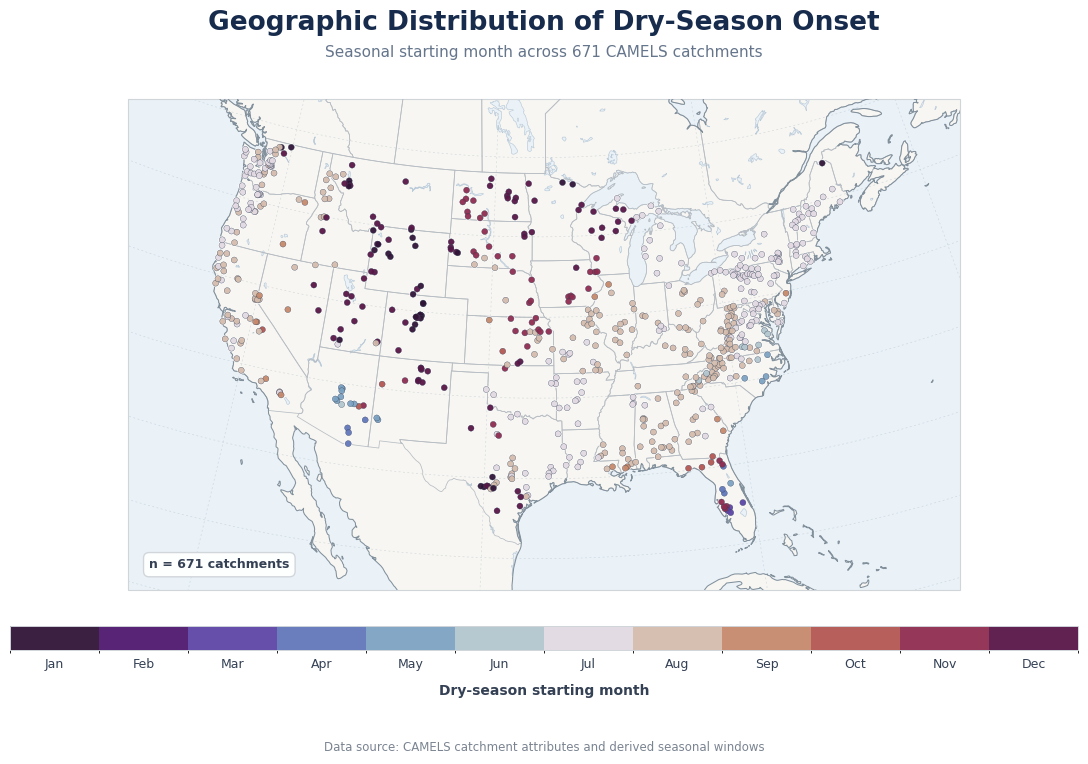

Catchments mapped : 671
PNG (600 DPI)     : /content/drive/MyDrive/ecohydro_project/Project 2/outputs/figures/task0_3_dry_season_start_map.png
Vector PDF        : /content/drive/MyDrive/ecohydro_project/Project 2/outputs/figures/task0_3_dry_season_start_map.pdf


In [36]:
# STAGE 0 — MAP: DRY-SEASON MAP


import sys
import subprocess

# Install Cartopy if unavailable
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "cartopy"
    ])
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable


# 1. LOAD AND PREPARE DATA


camels = pd.read_csv(
    PROCESSED / 'camels_catchment_attributes.csv',
    dtype={'gauge_id': str}
)

seasons['gauge_id'] = seasons['gauge_id'].astype(str)

map_df = seasons.merge(
    camels[['gauge_id', 'gauge_lat', 'gauge_lon']],
    on='gauge_id',
    how='left',
    validate='one_to_one'
)

# Data validation
assert map_df['gauge_lat'].notna().all(), \
    "Missing catchment latitude values."

assert map_df['gauge_lon'].notna().all(), \
    "Missing catchment longitude values."

assert map_df['dry_month_1'].between(1, 12).all(), \
    "Dry-season starting months must be between 1 and 12."

assert len(map_df) == 671, \
    f"Expected 671 catchments, found {len(map_df)}."


# 2. PUBLICATION STYLE


mpl.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.facecolor': '#FFFFFF',
    'savefig.facecolor': '#FFFFFF',
    'axes.edgecolor': '#D0D5DA',
    'axes.linewidth': 0.8,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})


# 3. DISCRETE CYCLIC MONTH COLOUR PALETTE

month_names = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

# Twelve evenly distributed colours from a cyclic palette
base_cmap = plt.get_cmap('twilight_shifted')

month_colors = base_cmap(
    np.linspace(0, 1, 12, endpoint=False)
)

month_cmap = ListedColormap(
    month_colors,
    name='dry_season_months'
)

# Month 1 -> January, Month 12 -> December
bounds = np.arange(0.5, 13.5, 1)

month_norm = BoundaryNorm(
    bounds,
    month_cmap.N
)


# 4. CREATE MAP

fig = plt.figure(figsize=(12, 8), facecolor='#FFFFFF')

# Albers Equal Area projection
ax = fig.add_axes([
    0.055, 0.17, 0.89, 0.69
], projection=ccrs.AlbersEqualArea(
    central_longitude=-96,
    central_latitude=37.5
))

# Continental United States
ax.set_extent(
    [-125, -66, 23, 51],
    crs=ccrs.PlateCarree()
)

# Background
ax.set_facecolor('#EAF2F8')

# Ocean
ax.add_feature(
    cfeature.OCEAN,
    facecolor='#EAF2F8',
    zorder=0
)

# Land
ax.add_feature(
    cfeature.LAND,
    facecolor='#F7F6F2',
    edgecolor='none',
    zorder=1
)

# Lakes
ax.add_feature(
    cfeature.LAKES,
    facecolor='#EAF2F8',
    edgecolor='#B8C9D8',
    linewidth=0.45,
    zorder=2
)

# State boundaries
ax.add_feature(
    cfeature.STATES,
    edgecolor='#B7BDC3',
    linewidth=0.55,
    zorder=3
)

# Coastlines
ax.coastlines(
    resolution='50m',
    color='#82909C',
    linewidth=0.75,
    zorder=4
)

# Subtle geographic gridlines
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,
    linewidth=0.45,
    color='#AAB8C2',
    alpha=0.48,
    linestyle=(0, (3, 4)),
    zorder=2
)


# 5. CATCHMENT LOCATIONS

# White halo underneath the points
ax.scatter(
    map_df['gauge_lon'],
    map_df['gauge_lat'],
    transform=ccrs.PlateCarree(),
    s=31,
    color='white',
    edgecolors='none',
    alpha=0.95,
    zorder=5
)

# Main catchment points
sc = ax.scatter(
    map_df['gauge_lon'],
    map_df['gauge_lat'],
    c=map_df['dry_month_1'],
    cmap=month_cmap,
    norm=month_norm,
    transform=ccrs.PlateCarree(),
    s=19,
    alpha=0.95,
    edgecolors='#344054',
    linewidths=0.25,
    zorder=6
)


# 6. DISCRETE MONTH COLORBAR

cbar = fig.colorbar(
    sc,
    ax=ax,
    orientation='horizontal',
    boundaries=bounds,
    ticks=np.arange(1, 13),
    spacing='uniform',
    pad=0.065,
    fraction=0.045,
    aspect=45
)

cbar.set_ticklabels([
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
])

cbar.set_label(
    'Dry-season starting month',
    fontsize=10,
    fontweight='bold',
    labelpad=9,
    color='#344054'
)

cbar.ax.tick_params(
    labelsize=9,
    length=0,
    pad=6,
    colors='#344054'
)

cbar.outline.set_edgecolor('#D0D5DA')
cbar.outline.set_linewidth(0.7)


# 7. TITLE AND ANNOTATIONS

fig.text(
    0.5, 0.955,
    'Geographic Distribution of Dry-Season Onset',
    ha='center',
    va='center',
    fontsize=19,
    fontweight='bold',
    color='#172B4D'
)

fig.text(
    0.5, 0.918,
    'Seasonal starting month across 671 CAMELS catchments',
    ha='center',
    va='center',
    fontsize=11,
    color='#65758B'
)

# Catchment count annotation
ax.text(
    0.025, 0.045,
    f'n = {len(map_df):,} catchments',
    transform=ax.transAxes,
    fontsize=9,
    fontweight='bold',
    color='#344054',
    bbox=dict(
        boxstyle='round,pad=0.45',
        facecolor='white',
        edgecolor='#D0D5DA',
        alpha=0.95
    ),
    zorder=10
)

# Source annotation
fig.text(
    0.5, 0.045,
    'Data source: CAMELS catchment attributes and derived seasonal windows',
    ha='center',
    fontsize=8.5,
    color='#7A8491'
)


# 8. EXPORT PUBLICATION-QUALITY FIGURES

fig_path = OUTPUTS / 'figures'
fig_path.mkdir(parents=True, exist_ok=True)

png_file = fig_path / 'task0_3_dry_season_start_map.png'
pdf_file = fig_path / 'task0_3_dry_season_start_map.pdf'

fig.savefig(
    png_file,
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    pdf_file,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print(f"Catchments mapped : {len(map_df)}")
print(f"PNG (600 DPI)     : {png_file}")
print(f"Vector PDF        : {pdf_file}")
print("=" * 60)


In [19]:
# STAGE 0 — LABELLED RECHARGE-DRY SEASON PAIRS


seasons = pd.read_csv(
    PROCESSED / 'task0_3_season_definitions_v2.csv',
    dtype={'gauge_id': str}
)

seasons['dry_months'] = seasons['dry_months'].apply(
    lambda x: [int(v) for v in x.strip('[]').split(',')]
)
seasons['recharge_months'] = seasons['recharge_months'].apply(
    lambda x: [int(v) for v in x.strip('[]').split(',')]
)

season_pairs = []

for _, row in seasons.iterrows():
    dry_months = row['dry_months']

    for dry_start_year in range(1980, 2015):

        # Build the three dry-season monthly periods sequentially.
        # If the month number decreases, the calendar year increases.
        dry_periods = []
        current_year = dry_start_year
        previous_month = None

        for month in dry_months:
            if previous_month is not None and month < previous_month:
                current_year += 1

            dry_periods.append(
                pd.Period(f'{current_year}-{month:02d}', freq='M')
            )
            previous_month = month

        recharge_periods = [
            dry_periods[0] - pd.offsets.MonthEnd(k + 1)
            for k in range(6)
        ][::-1]

        recharge_start = recharge_periods[0].to_timestamp()
        recharge_end = recharge_periods[-1].to_timestamp(how='end')
        dry_start = dry_periods[0].to_timestamp()
        dry_end = dry_periods[-1].to_timestamp(how='end')


        # Keep seasons whose final month is within the data record
        if dry_periods[-1] > pd.Period('2014-12', freq='M'):
            continue

        season_pairs.append({
            'gauge_id': row['gauge_id'],
            'season_year': dry_start_year,
            'recharge_start': recharge_start,
            'recharge_end': recharge_end,
            'dry_start': dry_start,
            'dry_end': dry_end,
            'dry_months': dry_months,
            'recharge_months': row['recharge_months'],
        })

season_pairs = pd.DataFrame(season_pairs)

# Date-order and overlap checks
season_pairs['recharge_before_dry'] = (
    season_pairs['recharge_end'] < season_pairs['dry_start']
)

season_pairs['months_do_not_overlap'] = season_pairs.apply(
    lambda row: len(
        set(row['recharge_months']) &
        set(row['dry_months'])
    ) == 0,
    axis=1
)

# Critical new check: every dry window must contain exactly three months
season_pairs['dry_window_length_months'] = season_pairs.apply(
    lambda row: len(
        pd.period_range(
            start=row['dry_start'],
            end=row['dry_end'],
            freq='M'
        )
    ),
    axis=1
)

assert season_pairs['recharge_before_dry'].all()
assert season_pairs['months_do_not_overlap'].all()
assert season_pairs['dry_window_length_months'].eq(3).all()
assert season_pairs['gauge_id'].nunique() == 671
assert season_pairs['dry_end'].max() < pd.Timestamp('2015-01-01')
assert (season_pairs['dry_end'].dt.day ==
        season_pairs['dry_end'].dt.days_in_month).all()
assert (season_pairs['recharge_end'].dt.day ==
        season_pairs['recharge_end'].dt.days_in_month).all()

season_pairs_path = (
    PROCESSED / 'task0_3_season_pairs_labelled_v3.csv'
)
season_pairs.to_csv(season_pairs_path, index=False)

print('Season-pair table shape:', season_pairs.shape)
print('Unique catchments:', season_pairs['gauge_id'].nunique())
print('Season-year range:',
      season_pairs['season_year'].min(),
      'to',
      season_pairs['season_year'].max())
print('Pairs with date-order problems:',
      (~season_pairs['recharge_before_dry']).sum())
print('Pairs with overlapping months:',
      (~season_pairs['months_do_not_overlap']).sum())
print('Pairs with dry-window length != 3 months:',
      (~season_pairs['dry_window_length_months'].eq(3)).sum())

# Dry seasons that cross into the next calendar year
crossing = season_pairs[
    season_pairs['dry_end'].dt.year > season_pairs['dry_start'].dt.year
]
print('\nDry seasons crossing a calendar year:', len(crossing),
      'pairs in', crossing['gauge_id'].nunique(), 'catchments')
assert len(crossing) > 0
assert (crossing['dry_window_length_months'] == 3).all()

# November-start dry seasons must run Nov -> Jan of the next year
nov = season_pairs[season_pairs['dry_months'].apply(lambda m: m[0] == 11)]
assert (nov['dry_start'].dt.month == 11).all()
assert (nov['dry_end'].dt.month == 1).all()
assert (nov['dry_end'] > nov['dry_start']).all()

print(crossing[['gauge_id', 'season_year', 'dry_months',
                'dry_start', 'dry_end']].head(3).to_string(index=False))
print(f'\nSaved: {season_pairs_path}')


Season-pair table shape: (23358, 11)
Unique catchments: 671
Season-year range: 1980 to 2014
Pairs with date-order problems: 0
Pairs with overlapping months: 0
Pairs with dry-window length != 3 months: 0

Dry seasons crossing a calendar year: 4318 pairs in 127 catchments
gauge_id  season_year  dry_months  dry_start                       dry_end
02231000         1980 [11, 12, 1] 1980-11-01 1981-01-31 23:59:59.999999999
02231000         1981 [11, 12, 1] 1981-11-01 1982-01-31 23:59:59.999999999
02231000         1982 [11, 12, 1] 1982-11-01 1983-01-31 23:59:59.999999999

Saved: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/task0_3_season_pairs_labelled_v3.csv


In [20]:
# STAGE 0 — COMPLETENESS ON CORRECTED PAIRS


FINAL_PANEL = (
    PROCESSED / 'camels_daily_daymet_flow_panel_v4_airgr_pe.parquet'
)

season_pairs = pd.read_csv(
    PROCESSED / 'task0_3_season_pairs_labelled_v3.csv',
    parse_dates=['recharge_start', 'recharge_end',
                 'dry_start', 'dry_end'],
    dtype={'gauge_id': str}
)

daily = pd.read_parquet(
    FINAL_PANEL,
    columns=[
        'gauge_id', 'date', 'p_mm', 'tmax_c', 'tmin_c',
        'pe_mm', 'q_mm', 'flow_missing'
    ]
)

daily['year_month'] = daily['date'].dt.to_period('M').astype(str)

daily['stage0_day_missing'] = (
    daily['p_mm'].isna()
    | daily['tmax_c'].isna()
    | daily['tmin_c'].isna()
    | daily['pe_mm'].isna()
    | daily['q_mm'].isna()
    | daily['flow_missing']
)

monthly_counts = daily.groupby(
    ['gauge_id', 'year_month']
).agg(
    n_rows=('date', 'count'),
    n_missing=('stage0_day_missing', 'sum')
).reset_index()

count_lookup = {
    (row.gauge_id, row.year_month): row.n_rows
    for row in monthly_counts.itertuples(index=False)
}

missing_lookup = {
    (row.gauge_id, row.year_month): row.n_missing
    for row in monthly_counts.itertuples(index=False)
}


def window_stats(gauge_id, start_date, end_date):
    periods = pd.period_range(
        start=start_date,
        end=end_date,
        freq='M'
    ).astype(str)

    expected_days = sum(
        pd.Period(period).days_in_month
        for period in periods
    )

    observed_rows = sum(
        count_lookup.get((gauge_id, period), 0)
        for period in periods
    )

    missing_days = sum(
        missing_lookup.get((gauge_id, period), 0)
        for period in periods
    )

    return expected_days, observed_rows, missing_days


recharge_stats = []
dry_stats = []

for row in season_pairs.itertuples(index=False):
    recharge_stats.append(
        window_stats(
            row.gauge_id,
            row.recharge_start,
            row.recharge_end
        )
    )

    dry_stats.append(
        window_stats(
            row.gauge_id,
            row.dry_start,
            row.dry_end
        )
    )

recharge_stats = pd.DataFrame(
    recharge_stats,
    columns=[
        'recharge_expected_days',
        'recharge_observed_days',
        'recharge_missing_days'
    ]
)

dry_stats = pd.DataFrame(
    dry_stats,
    columns=[
        'dry_expected_days',
        'dry_observed_days',
        'dry_missing_days'
    ]
)

season_pairs = pd.concat(
    [season_pairs, recharge_stats, dry_stats],
    axis=1
)


assert season_pairs['dry_expected_days'].min() >= 89

season_pairs['recharge_complete'] = (
    (season_pairs['recharge_expected_days'] > 0)
    & (season_pairs['recharge_observed_days']
       == season_pairs['recharge_expected_days'])
    & (season_pairs['recharge_missing_days'] == 0)
)

season_pairs['dry_complete'] = (
    (season_pairs['dry_expected_days'] > 0)
    & (season_pairs['dry_observed_days']
       == season_pairs['dry_expected_days'])
    & (season_pairs['dry_missing_days'] == 0)
)

season_pairs['season_pair_complete'] = (
    season_pairs['recharge_complete']
    & season_pairs['dry_complete']
)

season_pairs_path = (
    PROCESSED / 'task0_3_season_pairs_completeness_v3.csv'
)
season_pairs.to_csv(season_pairs_path, index=False)

print('Total candidate season pairs:', len(season_pairs))
print('Complete recharge seasons:',
      season_pairs['recharge_complete'].sum())
print('Complete dry seasons:',
      season_pairs['dry_complete'].sum())
print('Complete recharge-dry pairs:',
      season_pairs['season_pair_complete'].sum())
print('Incomplete recharge-dry pairs:',
      (~season_pairs['season_pair_complete']).sum())

print('\nDry-window day-count summary:')
print(
    season_pairs['dry_expected_days']
    .describe()
    .to_string()
)

print(f'\nSaved: {season_pairs_path}')

Total candidate season pairs: 23358
Complete recharge seasons: 22686
Complete dry seasons: 22676
Complete recharge-dry pairs: 22565
Incomplete recharge-dry pairs: 793

Dry-window day-count summary:
count    23358.000000
mean        91.668251
std          0.689566
min         90.000000
25%         92.000000
50%         92.000000
75%         92.000000
max         92.000000

Saved: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/task0_3_season_pairs_completeness_v3.csv


In [22]:
# STAGE 0 — TASK 0.4 PRIMARY SAMPLE AND HUC-4 OVERLAY


import geopandas as gpd

season_pairs = pd.read_csv(
    PROCESSED / 'task0_3_season_pairs_completeness_v3.csv',
    parse_dates=['recharge_start', 'recharge_end',
                 'dry_start', 'dry_end'],
    dtype={'gauge_id': str}
)

camels = pd.read_csv(
    PROCESSED / 'camels_catchment_attributes.csv',
    dtype={'gauge_id': str}
)

# Count complete recharge-dry pairs per catchment
complete_counts = (
    season_pairs[season_pairs['season_pair_complete']]
    .groupby('gauge_id', as_index=False)
    .size()
    .rename(columns={'size': 'n_complete_pairs'})
)

primary = camels.merge(
    complete_counts,
    on='gauge_id',
    how='left',
    validate='one_to_one'
)

primary['n_complete_pairs'] = (
    primary['n_complete_pairs'].fillna(0).astype(int)
)

# Pre-specified primary-sample rules
primary['meets_snow_rule'] = primary['frac_snow'] < 0.2
primary['meets_season_rule'] = primary['n_complete_pairs'] >= 20
primary['in_primary_sample'] = (
    primary['meets_snow_rule'] & primary['meets_season_rule']
)

primary_ids = set(
    primary.loc[primary['in_primary_sample'], 'gauge_id']
)

# Keep only complete pairs from primary-sample catchments
primary_pairs = season_pairs[
    season_pairs['gauge_id'].isin(primary_ids)
    & season_pairs['season_pair_complete']
].copy()

print('Candidate catchments:', len(primary))
print('Catchments meeting snow rule:',
      primary['meets_snow_rule'].sum())
print('Catchments meeting 20-season rule:',
      primary['meets_season_rule'].sum())
print('Catchments in primary sample:',
      primary['in_primary_sample'].sum())
print('Complete pairs in primary sample:', len(primary_pairs))

# Attach HUC-4 codes only for primary-sample catchments
primary_gauges = primary[
    primary['in_primary_sample']
][
    ['gauge_id', 'huc_02', 'gauge_lat', 'gauge_lon']
]

gauges = gpd.GeoDataFrame(
    primary_gauges,
    geometry=gpd.points_from_xy(
        primary_gauges['gauge_lon'],
        primary_gauges['gauge_lat']
    ),
    crs='EPSG:4269'
)

huc4 = gpd.read_file(
    WBD_GPKG,
    layer='WBDHU4',
    columns=['huc4', 'name', 'geometry']
)

print('\nHUC-4 polygons:', len(huc4))
print('HUC-4 CRS:', huc4.crs)

gauges = gauges.to_crs(huc4.crs)

joined = gpd.sjoin(
    gauges,
    huc4,
    how='left',
    predicate='within'
)

# Keep one HUC-4 assignment per gauge
joined = joined.drop_duplicates(subset='gauge_id')

print('Primary-sample gauges with HUC-4:',
      joined['huc4'].notna().sum())
print('Primary-sample gauges without HUC-4:',
      joined['huc4'].isna().sum())

huc4_lookup = joined[['gauge_id', 'huc4']].copy()
huc4_lookup['huc4'] = huc4_lookup['huc4'].astype(str)

# Merge HUC-4 into the primary sample and complete pairs
primary = primary.merge(
    huc4_lookup,
    on='gauge_id',
    how='left',
    validate='one_to_one'
)

primary_pairs = primary_pairs.merge(
    huc4_lookup,
    on='gauge_id',
    how='left',
    validate='many_to_one'
)

# Save Task 0.4 outputs
primary_path = PROCESSED / 'task0_4_primary_sample_v3.csv'
primary_pairs_path = (
    PROCESSED / 'task0_4_primary_season_pairs_v3.csv'
)
huc4_path = PROCESSED / 'task0_4_gauge_huc4_v3.csv'

primary.to_csv(primary_path, index=False)
primary_pairs.to_csv(primary_pairs_path, index=False)
huc4_lookup.to_csv(huc4_path, index=False)

print('\nPrimary sample by HUC-2 region:')
print(
    primary[primary['in_primary_sample']]
    .groupby('huc_02')
    .agg(
        n_catchments=('gauge_id', 'count'),
        total_complete_pairs=('n_complete_pairs', 'sum')
    )
    .to_string()
)

print('\nHUC-4 clusters in primary sample:',
      primary.loc[primary['in_primary_sample'], 'huc4'].nunique())
print('HUC-4 clusters in complete primary pairs:',
      primary_pairs['huc4'].nunique())

print(f'\nSaved primary sample: {primary_path}')
print(f'Saved primary season pairs: {primary_pairs_path}')
print(f'Saved HUC-4 lookup: {huc4_path}')

Candidate catchments: 671
Catchments meeting snow rule: 477
Catchments meeting 20-season rule: 671
Catchments in primary sample: 477
Complete pairs in primary sample: 16066

HUC-4 polygons: 245
HUC-4 CRS: COMPD_CS["NAD83 + NAVD88 height",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4269"]],VERT_CS["NAVD88 height",VERT_DATUM["North American Vertical Datum 1988",2005],UNIT["metre",1],AXIS["Gravity-related height",UP],AUTHORITY["EPSG","5703"]]]
Primary-sample gauges with HUC-4: 477
Primary-sample gauges without HUC-4: 0

Primary sample by HUC-2 region:
        n_catchments  total_complete_pairs
huc_02                                    
1                  5                   169
2                 60                  2073
3                 92                  3040
4                 14                

In [23]:
# STAGE 0 — TASK 0.5 CONCENTRATION AND DRY-SEASON OUTCOME


FINAL_PANEL = (
    PROCESSED / 'camels_daily_daymet_flow_panel_v4_airgr_pe.parquet'
)

primary_pairs = pd.read_csv(
    PROCESSED / 'task0_4_primary_season_pairs_v3.csv',
    parse_dates=['recharge_start', 'recharge_end',
                 'dry_start', 'dry_end'],
    dtype={'gauge_id': str}
)

daily = pd.read_parquet(
    FINAL_PANEL,
    columns=[
        'gauge_id', 'date', 'p_mm', 'tmax_c', 'tmin_c',
        'pe_mm', 'q_mm', 'flow_missing'
    ]
)

# Sort once; then group by gauge for fast access
daily = daily.sort_values(['gauge_id', 'date']).reset_index(drop=True)

daily_by_gauge = {
    gauge_id: group.reset_index(drop=True)
    for gauge_id, group in daily.groupby('gauge_id', sort=False)
}


def gini(x):
    """
    Gini coefficient using the guide's formula.
    x must be a one-dimensional array of non-negative values.
    """
    x = np.sort(np.asarray(x, dtype=float))
    n = x.size
    cumulative = np.cumsum(x)

    if n == 0 or cumulative[-1] == 0:
        return np.nan

    return (n + 1 - 2 * cumulative.sum() / cumulative[-1]) / n


def calculate_season_row(row, gauge_daily):
    """
    Calculate recharge-season concentration, controls,
    and the following dry-season outcome for one season pair.
    """

    # Recharge-season daily data
    recharge = gauge_daily[
        (gauge_daily['date'] >= row.recharge_start)
        & (gauge_daily['date'] <= row.recharge_end)
    ].copy()

    # Dry-season daily data
    dry = gauge_daily[
        (gauge_daily['date'] >= row.dry_start)
        & (gauge_daily['date'] <= row.dry_end)
    ].copy()

    # Recharge-season precipitation concentration
    p_raw = recharge['p_mm'].to_numpy(dtype=float)

    # Set days below 1 mm to zero before calculating G_P
    p_thresholded = np.where(p_raw < 1.0, 0.0, p_raw)

    P_s = p_raw.sum()
    f = np.mean(p_thresholded == 0)

    wet_days = p_thresholded[p_thresholded > 0]

    if wet_days.size > 0:
        G_wet = gini(wet_days)
    else:
        G_wet = np.nan

    G_P = gini(p_thresholded)

    # Recharge-season controls
    T_recharge = (
        (recharge['tmax_c'] + recharge['tmin_c']) / 2
    ).mean()

    PE_recharge = recharge['pe_mm'].sum()

    # Antecedent flow: 30 days before the recharge season begins
    antecedent = gauge_daily[
        (gauge_daily['date'] >= row.recharge_start - pd.Timedelta(days=30))
        & (gauge_daily['date'] < row.recharge_start)
    ]

    q_ante = antecedent.loc[
        ~antecedent['flow_missing'], 'q_mm'
    ].mean()

    # Dry-season outcome and intervening climate
    q_dry_mean = dry['q_mm'].mean()

    if q_dry_mean > 0:
        ln_qdry = np.log(q_dry_mean)
    else:
        ln_qdry = np.nan

    P_dry = dry['p_mm'].sum()
    PE_dry = dry['pe_mm'].sum()

    return {
        'gauge_id': row.gauge_id,
        'season_year': row.season_year,
        'P_s': P_s,
        'G_P': G_P,
        'f': f,
        'G_wet': G_wet,
        'T_recharge': T_recharge,
        'PE_recharge': PE_recharge,
        'q_ante': q_ante,
        'q_dry_mean': q_dry_mean,
        'ln_qdry': ln_qdry,
        'P_dry': P_dry,
        'PE_dry': PE_dry,
    }


results = []

for row in primary_pairs.itertuples(index=False):
    gauge_daily = daily_by_gauge[row.gauge_id]
    results.append(
        calculate_season_row(row, gauge_daily)
    )

panel0 = pd.DataFrame(results)

print('Catchment-season panel shape:', panel0.shape)
print('Unique catchments:', panel0['gauge_id'].nunique())
print('Season-year range:',
      panel0['season_year'].min(), 'to',
      panel0['season_year'].max())

print('\nFirst five rows:')
print(panel0.head().to_string(index=False))

# Save the Task 0.5 panel
panel0_path = PROCESSED / 'task0_5_catchment_season_panel_v2.csv'
panel0.to_csv(panel0_path, index=False)

print(f'\nSaved: {panel0_path}')

Catchment-season panel shape: (16066, 13)
Unique catchments: 477
Season-year range: 1980 to 2014

First five rows:
gauge_id  season_year    P_s      G_P        f    G_wet  T_recharge  PE_recharge   q_ante  q_dry_mean   ln_qdry  P_dry     PE_dry
01073000         1980 401.11 0.880488 0.758242 0.505656    4.780687   287.419274      NaN    0.190069 -1.660366 226.96 335.335374
01073000         1981 527.95 0.858018 0.723757 0.486024    5.784309   317.633720 0.595663    0.404266 -0.905683 326.82 320.539907
01073000         1982 670.64 0.797636 0.618785 0.469161    3.468315   272.077690 2.126994    0.396880 -0.924121 191.25 317.786438
01073000         1983 825.84 0.808083 0.624309 0.489162    5.728646   299.844942 0.534742    0.203924 -1.590007 176.59 339.568277
01073000         1984 770.16 0.800773 0.626374 0.466775    5.169148   300.368904 4.121214    0.483048 -0.727640 187.83 328.814168

Saved: /content/drive/MyDrive/ecohydro_project/Project 2/data/processed/task0_5_catchment_season_panel_v

In [24]:
# STAGE 0 — TASK 0.5 CHECKS


panel0 = pd.read_csv(
    PROCESSED / 'task0_5_catchment_season_panel_v2.csv',
    dtype={'gauge_id': str}
)

# 1. G_P decomposition check
decomposition_error = (
    panel0['G_P']
    - (
        panel0['f']
        + (1 - panel0['f']) * panel0['G_wet']
    )
).abs()

max_decomposition_error = decomposition_error.max()

print('G_P decomposition check')
print(f'Maximum absolute error: {max_decomposition_error:.3e}')
print('Requirement: essentially zero, e.g. < 1e-10')

# 2. Within-catchment correlation between G_P and P_s
within_correlations = []

for gauge_id, group in panel0.groupby('gauge_id'):
    if group['G_P'].nunique() > 1:
        r = group['G_P'].corr(group['P_s'])

        if pd.notna(r):
            within_correlations.append(r)

within_correlations = np.array(within_correlations)

print('\nWithin-catchment correlation of G_P with P_s')
print(f'Catchments used: {len(within_correlations)}')
print(f'Mean correlation: {within_correlations.mean():.4f}')
print(f'Median correlation: {np.median(within_correlations):.4f}')
print(f'Minimum correlation: {within_correlations.min():.4f}')
print(f'Maximum correlation: {within_correlations.max():.4f}')

# 3. Zero dry-season flow
zero_flow = panel0[panel0['q_dry_mean'] == 0]

zero_flow_by_gauge = (
    zero_flow.groupby('gauge_id')
    .size()
    .rename('n_zero_flow_seasons')
    .reset_index()
)

season_counts = (
    panel0.groupby('gauge_id')
    .size()
    .rename('n_seasons')
    .reset_index()
)

zero_flow_summary = zero_flow_by_gauge.merge(
    season_counts,
    on='gauge_id',
    how='right'
)

zero_flow_summary['n_zero_flow_seasons'] = (
    zero_flow_summary['n_zero_flow_seasons'].fillna(0).astype(int)
)

zero_flow_summary['zero_flow_fraction'] = (
    zero_flow_summary['n_zero_flow_seasons']
    / zero_flow_summary['n_seasons']
)

frequent_zero_flow = zero_flow_summary[
    zero_flow_summary['zero_flow_fraction'] > 0.10
]

print('\nZero dry-season flow')
print(f'Seasons with zero flow: {len(zero_flow)}')
print(f'Catchments with any zero-flow season: '
      f'{(zero_flow_summary["n_zero_flow_seasons"] > 0).sum()}')
print(f'Catchments with zero flow in more than 10% of seasons: '
      f'{len(frequent_zero_flow)}')

if len(frequent_zero_flow) > 0:
    print('\nCatchments to analyse separately:')
    print(
        frequent_zero_flow[
            ['gauge_id', 'n_zero_flow_seasons',
             'n_seasons', 'zero_flow_fraction']
        ].to_string(index=False)
    )

# 4. Missing-value summary
check_columns = [
    'P_s', 'G_P', 'f', 'G_wet', 'T_recharge', 'PE_recharge',
    'q_ante', 'q_dry_mean', 'ln_qdry', 'P_dry', 'PE_dry'
]

print('\nMissing values before model-row filtering:')
print(panel0[check_columns].isna().sum().to_string())

# Save check outputs
checks_path = (
    PROCESSED / 'task0_5_catchment_season_panel_checks_v2.csv'
)

checks = pd.DataFrame({
    'check': [
        'max_G_P_decomposition_error',
        'mean_within_catchment_corr_GP_Ps',
        'median_within_catchment_corr_GP_Ps',
        'n_zero_flow_seasons',
        'n_catchments_with_zero_flow',
        'n_catchments_zero_flow_over_10pct'
    ],
    'value': [
        max_decomposition_error,
        within_correlations.mean(),
        np.median(within_correlations),
        len(zero_flow),
        (zero_flow_summary['n_zero_flow_seasons'] > 0).sum(),
        len(frequent_zero_flow)
    ]
})

checks.to_csv(checks_path, index=False)

print(f'\nSaved checks: {checks_path}')

G_P decomposition check
Maximum absolute error: 3.331e-16
Requirement: essentially zero, e.g. < 1e-10

Within-catchment correlation of G_P with P_s
Catchments used: 477
Mean correlation: -0.6430
Median correlation: -0.6494
Minimum correlation: -0.9313
Maximum correlation: -0.2347

Zero dry-season flow
Seasons with zero flow: 456
Catchments with any zero-flow season: 59
Catchments with zero flow in more than 10% of seasons: 30

Catchments to analyse separately:
gauge_id  n_zero_flow_seasons  n_seasons  zero_flow_fraction
05123400                   18         34            0.529412
06440200                    4         25            0.160000
06441500                    7         30            0.233333
06470800                    6         34            0.176471
06847900                    7         35            0.200000
06879650                   11         35            0.314286
07226500                   18         33            0.545455
08050800                    3         29       

In [25]:
# STAGE 0 — FINALISE TASK 0.5 PANEL (STRICT q_ante, FLAGS)


FINAL_PANEL = (
    PROCESSED / 'camels_daily_daymet_flow_panel_v4_airgr_pe.parquet'
)

panel0 = pd.read_csv(
    PROCESSED / 'task0_5_catchment_season_panel_v2.csv',
    dtype={'gauge_id': str}
)

pairs = pd.read_csv(
    PROCESSED / 'task0_4_primary_season_pairs_v3.csv',
    parse_dates=['recharge_start'],
    dtype={'gauge_id': str}
)[['gauge_id', 'season_year', 'recharge_start']]

huc4 = pd.read_csv(
    PROCESSED / 'task0_4_gauge_huc4_v3.csv',
    dtype={'gauge_id': str, 'huc4': str}
)

daily = pd.read_parquet(
    FINAL_PANEL,
    columns=['gauge_id', 'date', 'q_mm', 'flow_missing']
)

# Flow series with unusable days set to NaN, indexed by date
daily.loc[daily['flow_missing'], 'q_mm'] = np.nan
flow_by_gauge = {
    g: grp.set_index('date')['q_mm'].sort_index()
    for g, grp in daily.groupby('gauge_id')
}

# Strict antecedent flow: all 30 days must exist and be valid
def strict_q_ante(gauge_id, recharge_start):
    window = flow_by_gauge[gauge_id].loc[
        recharge_start - pd.Timedelta(days=30):
        recharge_start - pd.Timedelta(days=1)
    ]
    if len(window) == 30 and window.notna().all():
        return window.mean()
    return np.nan

pairs['q_ante_strict'] = [
    strict_q_ante(r.gauge_id, r.recharge_start)
    for r in pairs.itertuples(index=False)
]

panel0 = panel0.merge(
    pairs[['gauge_id', 'season_year', 'q_ante_strict']],
    on=['gauge_id', 'season_year'],
    how='left',
    validate='one_to_one'
)

print('q_ante missing, old (partial windows allowed):',
      panel0['q_ante'].isna().sum())
print('q_ante missing, strict (30 valid days):',
      panel0['q_ante_strict'].isna().sum())

panel0 = panel0.rename(columns={'q_ante': 'q_ante_partial'})
panel0 = panel0.rename(columns={'q_ante_strict': 'q_ante'})

# Zero-flow flags
panel0['zero_flow_season'] = panel0['q_dry_mean'] == 0
zf = panel0.groupby('gauge_id')['zero_flow_season'].mean()
zero_flow_catchments = set(zf[zf > 0.10].index)
panel0['zero_flow_gt10pct'] = panel0['gauge_id'].isin(zero_flow_catchments)

# HUC-4
panel0 = panel0.merge(huc4, on='gauge_id', how='left', validate='many_to_one')

# Rows with undefined G_P
bad_gp = panel0[panel0['G_P'].isna()]
print('\nSeasons with undefined G_P:')
print(bad_gp[['gauge_id', 'season_year', 'P_s', 'f']].to_string(index=False))

# Row eligibility for the Stage 0 model
model_vars = ['G_P', 'P_s', 'T_recharge', 'PE_recharge',
              'q_ante', 'ln_qdry', 'P_dry', 'PE_dry']
panel0['has_all_model_vars'] = panel0[model_vars].notna().all(axis=1)
panel0['primary_model_row'] = (
    panel0['has_all_model_vars'] & ~panel0['zero_flow_gt10pct']
)

m = panel0[panel0['primary_model_row']]
print('\nRows in panel:', len(panel0))
print('Rows with all model variables:', panel0['has_all_model_vars'].sum())
print('Frequent zero-flow catchments (>10%):', len(zero_flow_catchments))
print('Primary model rows:', len(m))
print('Primary model catchments:', m['gauge_id'].nunique())
print('Primary model HUC-4 clusters:', m['huc4'].nunique())
print('Min seasons per model catchment:',
      m.groupby('gauge_id').size().min())

panel0.to_csv(PROCESSED / 'task0_5_catchment_season_panel_v3.csv',
              index=False)
pd.Series(sorted(zero_flow_catchments), name='gauge_id').to_csv(
    PROCESSED / 'task0_5_zero_flow_catchments_gt10pct.csv', index=False)
print('\nSaved task0_5_catchment_season_panel_v3.csv')

q_ante missing, old (partial windows allowed): 140
q_ante missing, strict (30 valid days): 143

Seasons with undefined G_P:
gauge_id  season_year  P_s   f
10258500         2009 0.76 1.0
10259200         2009 0.00 1.0

Rows in panel: 16066
Rows with all model variables: 15469
Frequent zero-flow catchments (>10%): 30
Primary model rows: 14863
Primary model catchments: 447
Primary model HUC-4 clusters: 112
Min seasons per model catchment: 24

Saved task0_5_catchment_season_panel_v3.csv


In [27]:
# STAGE 0 — MEAN WET-DAY DEPTH, ARIDITY, P_MEAN


FINAL_PANEL = (
    PROCESSED / 'camels_daily_daymet_flow_panel_v4_airgr_pe.parquet'
)

pairs = pd.read_csv(
    PROCESSED / 'task0_4_primary_season_pairs_v3.csv',
    parse_dates=['recharge_start', 'recharge_end'],
    dtype={'gauge_id': str}
)

daily = pd.read_parquet(FINAL_PANEL, columns=['gauge_id', 'date', 'p_mm'])
daily = daily.sort_values(['gauge_id', 'date'])

p_by_gauge = {
    g: (grp['date'].to_numpy(), grp['p_mm'].to_numpy(dtype=float))
    for g, grp in daily.groupby('gauge_id')
}

# Recharge windows run from the first day of the start month
# to the last day of the end month
rows = []
for r in pairs.itertuples(index=False):
    dates, p = p_by_gauge[r.gauge_id]
    start = np.datetime64(r.recharge_start)
    end = np.datetime64(r.recharge_end + pd.offsets.MonthEnd(0))
    i0 = np.searchsorted(dates, start, side='left')
    i1 = np.searchsorted(dates, end, side='right')
    season_p = p[i0:i1]
    wet = season_p[season_p >= 1.0]
    rows.append({
        'gauge_id': r.gauge_id,
        'season_year': r.season_year,
        'n_days': len(season_p),
        'n_wet_days': len(wet),
        'wet_day_depth': wet.sum() / len(wet) if len(wet) > 0 else np.nan,
    })

wd = pd.DataFrame(rows)

# Every window must be a full recharge season
assert wd['n_days'].between(181, 184).all()

depth = (
    wd.groupby('gauge_id')
    .agg(mean_wet_day_depth=('wet_day_depth', 'mean'),
         n_seasons_used=('wet_day_depth', 'count'))
    .reset_index()
)

camels = pd.read_csv(
    PROCESSED / 'camels_catchment_attributes.csv',
    dtype={'gauge_id': str}
)

climate = depth.merge(
    camels[['gauge_id', 'aridity', 'p_mean']],
    on='gauge_id', how='left', validate='one_to_one'
)

assert len(climate) == 477
assert climate[['mean_wet_day_depth', 'aridity', 'p_mean']].notna().all().all()

climate.to_csv(PROCESSED / 'task0_6_climate_descriptors.csv', index=False)

print('Catchments:', len(climate))
print(climate[['mean_wet_day_depth', 'aridity', 'p_mean',
               'n_seasons_used']].describe().round(3).to_string())
print('\nCorrelation matrix:')
print(climate[['mean_wet_day_depth', 'aridity', 'p_mean']].corr().round(3)
      .to_string())
print('\nSaved task0_6_climate_descriptors.csv')

Catchments: 477
       mean_wet_day_depth  aridity   p_mean  n_seasons_used
count             477.000  477.000  477.000         477.000
mean               11.142    1.035    3.286          33.677
std                 2.522    0.574    1.301           2.247
min                 6.017    0.233    0.657          24.000
25%                 9.278    0.732    2.564          34.000
50%                10.884    0.851    3.271          34.000
75%                13.151    1.124    3.822          35.000
max                18.668    4.763    8.285          35.000

Correlation matrix:
                    mean_wet_day_depth  aridity  p_mean
mean_wet_day_depth               1.000   -0.182   0.459
aridity                         -0.182    1.000  -0.763
p_mean                           0.459   -0.763   1.000

Saved task0_6_climate_descriptors.csv


In [28]:
# STAGE 0 — AREA-WEIGHTED SCWDX80 STORAGE (EXACT PIXEL OVERLAP)


import xarray as xr
import geopandas as gpd
import shapely
from tqdm.auto import tqdm

ds = xr.open_dataset(STORAGE_FILE)
lat = ds['lat'].values
lon = ds['lon'].values
vals = ds['cwdx80'].values.astype('float64')       # shape (lat, lon)
res = 0.05

# Orientation and grid checks
assert vals.shape == (len(lat), len(lon))
assert np.all(np.diff(lat) > 0), 'lat is not south-to-north'
assert np.all(np.diff(lon) > 0), 'lon is not ascending'
assert np.allclose(np.diff(lat), res, atol=1e-6)
assert np.allclose(np.diff(lon), res, atol=1e-6)

vals[~np.isfinite(vals)] = np.nan
print('Finite pixels (%):', round(100 * np.isfinite(vals).mean(), 1))
print('Value range of finite pixels:',
      np.nanmin(vals), 'to', np.nanmax(vals))
assert np.nanmin(vals) >= 0, 'Negative storage values: check fill values'

# Primary-sample catchments and polygons
primary = pd.read_csv(
    PROCESSED / 'task0_4_primary_sample_v3.csv',
    dtype={'gauge_id': str}
)
primary = primary[primary['in_primary_sample']]
primary_ids = set(primary['gauge_id'])

bounds = gpd.read_file(BOUNDS_SHP)
print('Shapefile columns:', list(bounds.columns))
id_col = next(c for c in ['hru_id', 'gauge_id', 'GAUGE_ID']
              if c in bounds.columns)
bounds['gauge_id'] = bounds[id_col].astype(str).str.zfill(8)
bounds = bounds[bounds['gauge_id'].isin(primary_ids)]
if bounds.crs is None:
    bounds = bounds.set_crs(4269)
bounds = (
    bounds.dissolve(by='gauge_id').reset_index()[['gauge_id', 'geometry']]
    .to_crs(4326)
)
assert len(bounds) == len(primary_ids) == 477, len(bounds)


def extract_storage(geom):
    geom = shapely.make_valid(geom)
    poly_area = gpd.GeoSeries([geom], crs=4326).to_crs(5070).area.iloc[0]

    minx, miny, maxx, maxy = geom.bounds
    j0 = max(int(np.floor((minx - (lon[0] - res / 2)) / res)), 0)
    j1 = min(int(np.floor((maxx - (lon[0] - res / 2)) / res)), len(lon) - 1)
    i0 = max(int(np.floor((miny - (lat[0] - res / 2)) / res)), 0)
    i1 = min(int(np.floor((maxy - (lat[0] - res / 2)) / res)), len(lat) - 1)

    if i0 > i1 or j0 > j1:
        return np.nan, 0.0, 0.0, 0

    ii, jj = np.meshgrid(np.arange(i0, i1 + 1), np.arange(j0, j1 + 1),
                         indexing='ij')
    ii, jj = ii.ravel(), jj.ravel()

    boxes = shapely.box(lon[jj] - res / 2, lat[ii] - res / 2,
                        lon[jj] + res / 2, lat[ii] + res / 2)
    hit = shapely.intersects(boxes, geom)
    ii, jj, boxes = ii[hit], jj[hit], boxes[hit]
    inter = shapely.intersection(boxes, geom)

    keep = ~shapely.is_empty(inter)
    ii, jj, inter = ii[keep], jj[keep], inter[keep]
    areas = gpd.GeoSeries(inter, crs=4326).to_crs(5070).area.values

    v = vals[ii, jj]
    valid = np.isfinite(v)

    if valid.sum() == 0:
        return np.nan, 0.0, areas.sum() / poly_area, len(areas)

    mean_val = np.sum(areas[valid] * v[valid]) / np.sum(areas[valid])
    valid_fraction = areas[valid].sum() / poly_area
    coverage = areas.sum() / poly_area
    return mean_val, valid_fraction, coverage, len(areas)


rows = []
for r in tqdm(bounds.itertuples(index=False), total=len(bounds),
              desc='Storage extraction'):
    m, vf, cov, n = extract_storage(r.geometry)
    rows.append({'gauge_id': r.gauge_id, 'SCWDX80_mean_mm': m,
                 'valid_fraction': vf, 'coverage_ratio': cov,
                 'n_pixels': n})

storage = pd.DataFrame(rows)
storage['storage_coverage_flag'] = storage['valid_fraction'] < 0.90

# Cross-check: nearest-pixel value at each gauge
gp = primary[['gauge_id', 'gauge_lat', 'gauge_lon']].copy()
gp['nearest_pixel_value'] = [
    float(ds['cwdx80'].sel(lat=la, lon=lo, method='nearest'))
    for la, lo in zip(gp['gauge_lat'], gp['gauge_lon'])
]
storage = storage.merge(gp[['gauge_id', 'nearest_pixel_value']],
                        on='gauge_id', validate='one_to_one')

ok = storage.dropna(subset=['SCWDX80_mean_mm', 'nearest_pixel_value'])
r_check = ok['SCWDX80_mean_mm'].corr(ok['nearest_pixel_value'])

print('\nCatchments processed:', len(storage))
print('Catchments with no storage value:',
      storage['SCWDX80_mean_mm'].isna().sum())
print('Polygon coverage ratio (min / median):',
      round(storage['coverage_ratio'].min(), 3),
      round(storage['coverage_ratio'].median(), 3))
print('Catchments with valid coverage < 90%:',
      storage['storage_coverage_flag'].sum())
print(storage.loc[storage['storage_coverage_flag'],
                  ['gauge_id', 'valid_fraction',
                   'SCWDX80_mean_mm']].to_string(index=False))
print('\nStorage summary (mm):')
print(storage['SCWDX80_mean_mm'].describe().round(2).to_string())
print(f'\nCorrelation, area-weighted mean vs nearest pixel: {r_check:.3f}')
print('(a value near zero would indicate an orientation error)')

storage.to_csv(PROCESSED / 'task0_6_storage_v2.csv', index=False)
print('\nSaved task0_6_storage_v2.csv')

Finite pixels (%): 28.2
Value range of finite pixels: 9.009998757392168e-05 to 33052.91015625
Shapefile columns: ['hru_id', 'ann_P', 'lon_cen', 'lat_cen', 'AREA', 'elev_mean', 'ave_T', 'july_T', 'Perimeter', 'geometry']


Storage extraction:   0%|          | 0/477 [00:00<?, ?it/s]


Catchments processed: 477
Catchments with no storage value: 0
Polygon coverage ratio (min / median): 1.0 1.0
Catchments with valid coverage < 90%: 1
gauge_id  valid_fraction  SCWDX80_mean_mm
10259200        0.429886       258.661132

Storage summary (mm):
count     477.00
mean      232.60
std       154.59
min        31.64
25%       143.55
50%       185.61
75%       274.52
max      1366.98

Correlation, area-weighted mean vs nearest pixel: 0.877
(a value near zero would indicate an orientation error)

Saved task0_6_storage_v2.csv


In [29]:
# STAGE 0 — STORAGE VS CLIMATE CHECKS


storage = pd.read_csv(PROCESSED / 'task0_6_storage_v2.csv',
                      dtype={'gauge_id': str})
climate = pd.read_csv(PROCESSED / 'task0_6_climate_descriptors.csv',
                      dtype={'gauge_id': str})
panel0 = pd.read_csv(PROCESSED / 'task0_5_catchment_season_panel_v3.csv',
                     dtype={'gauge_id': str})

desc = climate.merge(storage, on='gauge_id', validate='one_to_one')
model_ids = set(panel0.loc[panel0['primary_model_row'], 'gauge_id'])
desc['in_model_sample'] = desc['gauge_id'].isin(model_ids)

def report(d, label):
    d = d.dropna(subset=['SCWDX80_mean_mm'])
    r_arid = d['SCWDX80_mean_mm'].corr(d['aridity'])
    r_depth = d['SCWDX80_mean_mm'].corr(d['mean_wet_day_depth'])
    d = d.copy()
    d['storage_tercile'] = pd.qcut(d['SCWDX80_mean_mm'], 3,
                                   labels=['low', 'medium', 'high'])
    terc = d.groupby('storage_tercile', observed=True).agg(
        n=('gauge_id', 'count'),
        storage_min=('SCWDX80_mean_mm', 'min'),
        storage_max=('SCWDX80_mean_mm', 'max'),
        aridity_min=('aridity', 'min'),
        aridity_max=('aridity', 'max'))
    print(f'\n=== {label} (n = {len(d)}) ===')
    print(f'r(storage, aridity)            = {r_arid:.3f}')
    print(f'r(storage, mean wet-day depth) = {r_depth:.3f}')
    print(f'|r(storage, aridity)| > 0.7 ?  {abs(r_arid) > 0.7}')
    print(terc.round(3).to_string())
    return r_arid, r_depth

report(desc, 'Primary sample (477)')
report(desc[desc['in_model_sample']], 'Primary model sample')

desc.to_csv(PROCESSED / 'task0_6_catchment_descriptors_v2.csv', index=False)
print('\nSaved task0_6_catchment_descriptors_v2.csv')


=== Primary sample (477) (n = 477) ===
r(storage, aridity)            = 0.027
r(storage, mean wet-day depth) = 0.471
|r(storage, aridity)| > 0.7 ?  False
                   n  storage_min  storage_max  aridity_min  aridity_max
storage_tercile                                                         
low              159       31.641      159.924        0.543        3.039
medium           159      160.206      237.049        0.482        2.673
high             159      237.294     1366.981        0.233        4.763

=== Primary model sample (n = 447) ===
r(storage, aridity)            = -0.056
r(storage, mean wet-day depth) = 0.500
|r(storage, aridity)| > 0.7 ?  False
                   n  storage_min  storage_max  aridity_min  aridity_max
storage_tercile                                                         
low              149       57.699      159.227        0.543        3.039
medium           149      159.720      219.793        0.482        2.673
high             149      221.97

0.6 completed -------------

###0.7

In [30]:
# STAGE 0 — RULE NOTE, OVERLAP CHECK, MODEL PANEL


panel0 = pd.read_csv(
    PROCESSED / 'task0_5_catchment_season_panel_v3.csv',
    dtype={'gauge_id': str, 'huc4': str}
)
model = panel0[panel0['primary_model_row']].copy()

# Computed on the Task 0.5 seasonal panel before model-row exclusions,
# restricted to rows with a defined G_P.
sd_panel = panel0[panel0['G_P'].notna()].copy()
sd_panel['GP_dev'] = (
    sd_panel['G_P']
    - sd_panel.groupby('gauge_id')['G_P'].transform('mean')
)
sd_w = sd_panel['GP_dev'].std(ddof=1)
n_sd_w = len(sd_panel)

pd.DataFrame({'sd_w': [sd_w], 'n_rows_sd_w': [n_sd_w]}).to_csv(
    PROCESSED / 'task0_7_sd_w_v2.csv', index=False)
print(f'sd_w (Task 0.5 panel, defined G_P): {sd_w:.6f} '
      f'over {n_sd_w} rows, {sd_panel["gauge_id"].nunique()} catchments')

# ---- 1. Dated rule note, written BEFORE any model is fitted ----
note = f"""# Stage 0 rules fixed before the first-check model
Date: {TODAY}

- Candidate pool: 671 CAMELS catchments.
- Primary sample: 477 catchments (frac_snow < 0.2, >= 20 complete recharge-dry pairs).
- Complete pairs in the primary sample: {len(panel0)}.
- Catchments with zero dry-season flow in > 10% of seasons: {panel0.loc[panel0['zero_flow_gt10pct'], 'gauge_id'].nunique()}.
  Rule: these are excluded from the primary model and listed separately.
- Remaining zero-flow seasons: ln(flow) is undefined, so these rows are dropped.
- Rows with undefined G_P (no day >= 1 mm) are dropped.
- q_ante requires all 30 antecedent days present and valid.
- Primary model sample: {len(model)} rows, {model['gauge_id'].nunique()} catchments, {model['huc4'].nunique()} HUC-4 clusters.
- sd_w computed on the Task 0.5 seasonal panel (primary sample, defined G_P): {n_sd_w} rows.
- Model: ln_qdry ~ Gs + P + P_c2 + T + PE + q_ante + P_dry + PE_dry | gauge_id + season_year, SE clustered by HUC-4. No interaction terms.
- Decision rule: half-width of the 95% CI <= 5% -> Phase 1 as designed; > 5% -> mechanism experiments.
"""
note_path = NOTES / f'task0_prespecified_rules_{TODAY}.md'
note_path.write_text(note)
print(note)

# ---- 2. Overlap of seasonal totals ----
rows = []
for gid, g in model.groupby('gauge_id'):
    q1, q2 = g['G_P'].quantile([1 / 3, 2 / 3])
    n_ties = int(g['G_P'].duplicated().sum())
    if q1 >= q2:
        rows.append({'gauge_id': gid, 'status': 'degenerate_ties',
                     'n_ties': n_ties})
        continue
    low = g[g['G_P'] <= q1]
    high = g[g['G_P'] >= q2]
    assert not (set(low.index) & set(high.index))
    overlap = (low['P_s'].max() >= high['P_s'].min()
               and high['P_s'].max() >= low['P_s'].min())
    rows.append({
        'gauge_id': gid, 'status': 'ok', 'n_low': len(low),
        'n_high': len(high), 'n_ties': n_ties,
        'low_Ps_min': low['P_s'].min(), 'low_Ps_max': low['P_s'].max(),
        'high_Ps_min': high['P_s'].min(), 'high_Ps_max': high['P_s'].max(),
        'totals_overlap': overlap})

ov = pd.DataFrame(rows)
ok = ov[ov['status'] == 'ok']
print('Catchments checked:', len(ok))
print('Degenerate (all-ties) catchments:', (ov['status'] != 'ok').sum())
print('Tied G_P values in total:', int(ov['n_ties'].sum()))
print('Catchments with overlapping totals:', int(ok['totals_overlap'].sum()),
      f"({100 * ok['totals_overlap'].mean():.1f}%)")
print('Catchments WITHOUT overlap (listed):')
print(ok.loc[~ok['totals_overlap'],
             ['gauge_id', 'low_Ps_min', 'low_Ps_max',
              'high_Ps_min', 'high_Ps_max']].to_string(index=False))
ov.to_csv(PROCESSED / 'task0_7_overlap_check_v2.csv', index=False)

# ---- 3. Export model panel ----
model['P'] = model['P_s']
model['P_c2'] = (model['P_s']
                 - model.groupby('gauge_id')['P_s'].transform('mean')) ** 2
out = model.rename(columns={'T_recharge': 'T', 'PE_recharge': 'PE'})[
    ['gauge_id', 'huc4', 'season_year', 'G_P', 'P', 'P_c2', 'T', 'PE',
     'q_ante', 'ln_qdry', 'P_dry', 'PE_dry']]
assert out.notna().all().all()
out.to_csv('/content/stage0_model_panel.csv', index=False)
out.to_csv(PROCESSED / 'task0_7_model_panel_v2.csv', index=False)
print('\nModel panel:', out.shape)

sd_w (Task 0.5 panel, defined G_P): 0.031079 over 16064 rows, 477 catchments
# Stage 0 rules fixed before the first-check model
Date: 2026-10-28

- Candidate pool: 671 CAMELS catchments.
- Primary sample: 477 catchments (frac_snow < 0.2, >= 20 complete recharge-dry pairs).
- Complete pairs in the primary sample: 16066.
- Catchments with zero dry-season flow in > 10% of seasons: 30.
  Rule: these are excluded from the primary model and listed separately.
- Remaining zero-flow seasons: ln(flow) is undefined, so these rows are dropped.
- Rows with undefined G_P (no day >= 1 mm) are dropped.
- q_ante requires all 30 antecedent days present and valid.
- Primary model sample: 14863 rows, 447 catchments, 112 HUC-4 clusters.
- sd_w computed on the Task 0.5 seasonal panel (primary sample, defined G_P): 16064 rows.
- Model: ln_qdry ~ Gs + P + P_c2 + T + PE + q_ante + P_dry + PE_dry | gauge_id + season_year, SE clustered by HUC-4. No interaction terms.
- Decision rule: half-width of the 95% CI <=

In [31]:
# STAGE 0 — fixest MODEL IN R


import subprocess

subprocess.run(['Rscript', '-e',
    'if(!requireNamespace("fixest",quietly=TRUE)) '
    'install.packages("fixest", repos="https://cloud.r-project.org")'],
    capture_output=True, text=True)

r_script = '''
suppressMessages({library(data.table); library(fixest)})

panel0 <- fread("/content/stage0_model_panel.csv",
                colClasses = list(character = c("gauge_id", "huc4")))

sd_w <- as.numeric(fread("/content/stage0_sd_w.csv")$sd_w)
panel0[, Gs := G_P / sd_w]

r0 <- feols(Gs ~ P + P_c2 + T + PE + q_ante | gauge_id + season_year,
            data = panel0)
usable <- sd(resid(r0))

m0 <- feols(ln_qdry ~ Gs + P + P_c2 + T + PE + q_ante + P_dry + PE_dry
            | gauge_id + season_year, data = panel0, cluster = ~huc4)

b  <- coef(m0)[["Gs"]]
ci <- as.numeric(confint(m0)["Gs", ])
pct <- 100 * (exp(c(b, ci[1], ci[2])) - 1)
half_width <- (pct[3] - pct[2]) / 2

summ <- data.frame(
  sd_w = sd_w, usable_variation = usable,
  coef_Gs = b, effect_pct = pct[1], ci_low_pct = pct[2],
  ci_high_pct = pct[3], half_width_pct = half_width,
  nobs_model = nobs(m0), nobs_panel = nrow(panel0),
  n_catchments = uniqueN(panel0$gauge_id),
  n_huc4 = uniqueN(panel0$huc4),
  within_r2 = as.numeric(r2(m0, "wr2")))
write.csv(summ, "/content/stage0_model_summary.csv", row.names = FALSE)

ct <- as.data.frame(coeftable(m0))
ct$term <- rownames(ct)
write.csv(ct, "/content/stage0_model_coefs.csv", row.names = FALSE)
print(summary(m0))
'''
open('/content/stage0_model.R', 'w').write(r_script)

pd.read_csv(PROCESSED / 'task0_7_sd_w_v2.csv').to_csv(
    '/content/stage0_sd_w.csv', index=False)

res = subprocess.run(['Rscript', '/content/stage0_model.R'],
                     capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('R model failed')

summ = pd.read_csv('/content/stage0_model_summary.csv')
print(summ.T.to_string(header=False))
summ.to_csv(OUTPUTS / 'tables' / 'task0_7_model_summary_v2.csv', index=False)
pd.read_csv('/content/stage0_model_coefs.csv').to_csv(
    OUTPUTS / 'tables' / 'task0_7_model_coefs_v2.csv', index=False)

OLS estimation, Dep. Var.: ln_qdry
Observations: 14,863
Fixed-effects: gauge_id: 447,  season_year: 35
Standard-errors: Clustered (huc4) 
           Estimate  Std. Error   t value   Pr(>|t|)    
Gs     -0.041248167 0.016459345 -2.506064 1.3658e-02 *  
P       0.001824846 0.000307894  5.926872 3.5415e-08 ***
P_c2   -0.000000607 0.000000264 -2.302749 2.3157e-02 *  
T       0.102597371 0.047032837  2.181399 3.1263e-02 *  
PE     -0.009929488 0.002108287 -4.709743 7.2242e-06 ***
q_ante -0.000656167 0.007885978 -0.083207 9.3384e-01    
P_dry   0.006468358 0.000460560 14.044539  < 2.2e-16 ***
PE_dry -0.011359915 0.001611721 -7.048314 1.6208e-10 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1
RMSE: 0.913721     Adj. R2: 0.761895
                 Within R2: 0.357581

sd_w                  0.031079
usable_variation      0.744628
coef_Gs              -0.041248
effect_pct           -4.040904
ci_low_pct           -7.120149
ci_high_pct          -0.859572
half_width_pct       

In [32]:
# STAGE 0 — PYTHON CROSS-CHECK OF THE fixest RESULT


import statsmodels.formula.api as smf

d = pd.read_csv('/content/stage0_model_panel.csv',
                dtype={'gauge_id': str, 'huc4': str})
summ = pd.read_csv('/content/stage0_model_summary.csv').iloc[0]

sd_w = float(pd.read_csv(PROCESSED / 'task0_7_sd_w_v2.csv')['sd_w'].iloc[0])
d['Gs'] = d['G_P'] / sd_w
print(f'sd_w  Python: {sd_w:.8f} | R: {summ.sd_w:.8f}')

fit = smf.ols('ln_qdry ~ Gs + P + P_c2 + T + PE + q_ante + P_dry + PE_dry'
              ' + C(gauge_id) + C(season_year)', data=d).fit()
b_py = fit.params['Gs']
print(f'coef(Gs) Python: {b_py:.8f} | R: {summ.coef_Gs:.8f}')
assert abs(b_py - summ.coef_Gs) < 1e-6, 'Python and R coefficients differ'

codes = pd.factorize(d['huc4'])[0]
fc = fit.get_robustcov_results(cov_type='cluster', groups=codes)
i = list(fit.params.index).index('Gs')
print(f'cluster SE (statsmodels): {fc.bse[i]:.6f}')
print('Note: fixest and statsmodels use different small-sample corrections, '
      'so SEs differ slightly; the coefficient must match.')
print('\nCOEFFICIENT CROSS-CHECK PASSED')

sd_w  Python: 0.03107864 | R: 0.03107864
coef(Gs) Python: -0.04124817 | R: -0.04124817
cluster SE (statsmodels): 0.016713
Note: fixest and statsmodels use different small-sample corrections, so SEs differ slightly; the coefficient must match.

COEFFICIENT CROSS-CHECK PASSED


0.7complete

###0.8

In [35]:
# STAGE 0 — TASK 0.8 FIRST-CHECK NOTE (GENERATED)


summ = pd.read_csv(OUTPUTS / 'tables' / 'task0_7_model_summary_v2.csv').iloc[0]
ov = pd.read_csv(PROCESSED / 'task0_7_overlap_check_v2.csv',
                 dtype={'gauge_id': str})
desc = pd.read_csv(PROCESSED / 'task0_6_catchment_descriptors_v2.csv',
                   dtype={'gauge_id': str})
panel0 = pd.read_csv(PROCESSED / 'task0_5_catchment_season_panel_v3.csv',
                     dtype={'gauge_id': str, 'huc4': str})
checks = pd.read_csv(
    PROCESSED / 'task0_5_catchment_season_panel_checks_v2.csv'
).set_index('check')['value']
pairs = pd.read_csv(PROCESSED / 'task0_3_season_pairs_completeness_v3.csv')
rr = pd.read_csv(PROCESSED / 'task0_2_runoff_ratio_check_v3.csv',
                 dtype={'gauge_id': str}).dropna(
    subset=['calculated_runoff_ratio', 'runoff_ratio'])
pe = pd.read_csv(OUTPUTS / 'tables' / 'task0_2_airgr_pe_exact_validation.csv')

r_rr = rr['calculated_runoff_ratio'].corr(rr['runoff_ratio'])
pe_max = pe['difference'].abs().max()
n_pairs_all = int(pairs['season_pair_complete'].sum())

# Storage-climate separability
r_sa = desc['SCWDX80_mean_mm'].corr(desc['aridity'])
r_sd = desc['SCWDX80_mean_mm'].corr(desc['mean_wet_day_depth'])
desc['tercile'] = pd.qcut(desc['SCWDX80_mean_mm'], 3,
                          labels=['low', 'medium', 'high'])
terc = desc.groupby('tercile', observed=True).agg(
    n=('gauge_id', 'count'),
    aridity_min=('aridity', 'min'), aridity_max=('aridity', 'max')
).round(3)
flagged = desc.loc[desc['valid_fraction'] < 0.90,
                   ['gauge_id', 'valid_fraction']]

# Overlap
ok = ov[ov['status'] == 'ok']
no_ov = ok.loc[~ok['totals_overlap'], 'gauge_id'].tolist()

# Decision logic: follows the actual numbers
hw = float(summ.half_width_pct)
lo, hi = float(summ.ci_low_pct), float(summ.ci_high_pct)
excludes_zero = not (lo <= 0 <= hi)
within_5 = (lo >= -5) and (hi <= 5)

if hw <= 5:
    decision = ('Half-width <= 5 percentage points: Phase 1 continues as '
                'designed, whatever the sign or size of the estimate.')
else:
    decision = ('Half-width > 5 percentage points: Phase 1 continues with '
                'the mechanism experiments (Stage 5) as the core of Paper 1; '
                'the observational estimate is reported with its '
                'uncertainty.')
sep_text = ('Storage and aridity |r| > 0.7: storage and climate are '
            'interpreted together in RQ2.' if abs(r_sa) > 0.7 else
            'Storage and aridity |r| <= 0.7: storage and aridity are '
            'treated as separable in this sample.')

note = f"""# First-check note (Stage 0, Task 0.8)
Date: {TODAY}
Forcing: Daymet (CAMELS v1p2). PE: airGR::PE_Oudin() with CAMELS gauge_lat.
Primary outcome: ln(mean dry-season flow). No interaction terms.

## Sample
- Candidate pool: 671 catchments; complete recharge-dry pairs in the pool: {n_pairs_all}.
- Primary sample: 477 catchments (frac_snow < 0.2, >= 20 complete pairs); {len(panel0)} complete pairs.
- Catchments with zero dry-season flow in > 10% of seasons: {panel0.loc[panel0['zero_flow_gt10pct'], 'gauge_id'].nunique()} (excluded from the primary model, listed separately).
- Primary model sample: {int(summ.nobs_model)} rows, {int(summ.n_catchments)} catchments, {int(summ.n_huc4)} HUC-4 clusters.

## Checks
- Runoff-ratio check (Oct 1989 - Sep 2009): r = {r_rr:.4f} over {len(rr)} catchments (requirement r > 0.95).
- Some substantial catchment-level differences remain and are documented in the validation output; their causes have not yet been resolved.
- PE vs airGR re-computation: max abs difference {pe_max:.2e} mm/day (CSV rounding).
- G_P decomposition: max abs error {checks['max_G_P_decomposition_error']:.2e}.
- Within-catchment correlation of G_P with P_s (primary sample): mean {checks['mean_within_catchment_corr_GP_Ps']:.3f}, median {checks['median_within_catchment_corr_GP_Ps']:.3f}.
- Python and R (fixest) coefficients agree.

## Storage and climate (primary sample)
- r(storage, aridity) = {r_sa:.3f}; r(storage, mean wet-day depth) = {r_sd:.3f}.
- Catchments with < 90% valid storage coverage: {flagged.to_dict('records')}.
- Aridity range within each storage tercile:
{terc.to_string()}

## Overlap of seasonal totals (model sample)
- {int(ok['totals_overlap'].sum())} of {len(ok)} catchments ({100 * ok['totals_overlap'].mean():.1f}%) have overlapping totals.
- No overlap (comparisons conditional on similar totals): {', '.join(no_ov)}.

## Usable variation
- Pooled within-catchment SD of G_P: {summ.sd_w:.5f}.
- SD of the residual of Gs after totals, controls and fixed effects: {summ.usable_variation:.3f}.
- sd_w sample: Task 0.5 seasonal panel, primary sample, defined G_P ({n_sd_w} rows).

## Main effect (no interaction terms; SE clustered by HUC-4)
- Effect per within-catchment SD of G_P: {summ.effect_pct:.2f}% in dry-season flow.
- 95% interval: {lo:.2f}% to {hi:.2f}%; half-width {hw:.2f} percentage points.
- Interval excludes zero: {excludes_zero}. Interval within +/-5%: {within_5}.
- Within R2: {summ.within_r2:.3f}.

## Decision
- {decision}
- {sep_text}

## Notes
- Estimates are associations conditional on rainfall total, evaporative demand, antecedent flow, catchment and year fixed effects.
- An earlier preliminary run is superseded: PE, season dates, flow flags, storage extraction and sample rules were corrected.
"""

note_path = NOTES / f'first_check_note_{TODAY}.md'
note_path.write_text(note)
print(note)

# Version log: duplicate-safe
vl_path = OUTPUTS / 'version_log_clean.csv'
vl = pd.read_csv(vl_path)
new = pd.DataFrame([
    {'dataset_id': 'SCWDX80_catchment_means', 'version': 'cwdx80, exact pixel overlap',
     'variables': 'cwdx80 (Stocker et al. 2023)', 'period': 'static',
     'resolution': '0.05 degree', 'download_date': TODAY,
     'source': 'https://doi.org/10.5281/zenodo.5515246',
     'local_path': str(STORAGE_FILE),
     'notes': 'Area-weighted with fractional pixel overlap (EPSG:5070 areas)'},
    {'dataset_id': 'first_check_result', 'version': TODAY,
     'variables': 'Effect of G_P on ln dry-season flow', 'period': '1980-2014',
     'resolution': 'catchment-season', 'download_date': TODAY,
     'source': 'Derived', 'local_path': str(note_path),
     'notes': f'{summ.effect_pct:.2f}% [{lo:.2f}, {hi:.2f}], half-width {hw:.2f}'}])
vl = pd.concat([vl, new], ignore_index=True).drop_duplicates(
    subset=['dataset_id', 'version'], keep='last')
vl.to_csv(vl_path, index=False)
print('\nSaved:', note_path)

# First-check note (Stage 0, Task 0.8)
Date: 2026-10-28
Forcing: Daymet (CAMELS v1p2). PE: airGR::PE_Oudin() with CAMELS gauge_lat.
Primary outcome: ln(mean dry-season flow). No interaction terms.

## Sample
- Candidate pool: 671 catchments; complete recharge-dry pairs in the pool: 22565.
- Primary sample: 477 catchments (frac_snow < 0.2, >= 20 complete pairs); 16066 complete pairs.
- Catchments with zero dry-season flow in > 10% of seasons: 30 (excluded from the primary model, listed separately).
- Primary model sample: 14863 rows, 447 catchments, 112 HUC-4 clusters.

## Checks
- Runoff-ratio check (Oct 1989 - Sep 2009): r = 0.9945 over 670 catchments (requirement r > 0.95).
- Some substantial catchment-level differences remain and are documented in the validation output; their causes have not yet been resolved.
- PE vs airGR re-computation: max abs difference 2.63e-07 mm/day (CSV rounding).
- G_P decomposition: max abs error 3.33e-16.
- Within-catchment correlation of G_P with P_s (p

In [34]:
# STAGE 0 — APPEND ROW ACCOUNTING TO THE NOTE


note_path = NOTES / f'first_check_note_{TODAY}.md'
text = note_path.read_text()

if '## Row accounting' not in text:
    panel0 = pd.read_csv(
        PROCESSED / 'task0_5_catchment_season_panel_v3.csv',
        dtype={'gauge_id': str, 'huc4': str}
    )
    desc = pd.read_csv(
        PROCESSED / 'task0_6_catchment_descriptors_v2.csv',
        dtype={'gauge_id': str}
    )
    camels = pd.read_csv(PROCESSED / 'camels_catchment_attributes.csv',
                         dtype={'gauge_id': str})

    n_all = len(panel0)
    n_complete = int(panel0['has_all_model_vars'].sum())
    n_model = int(panel0['primary_model_row'].sum())
    n_zero_seasons = int((panel0['q_dry_mean'] == 0).sum())
    n_gp_nan = int(panel0['G_P'].isna().sum())
    n_qante_nan = int(panel0['q_ante'].isna().sum())
    n_unique_missing = n_all - n_complete
    n_zf_catch_rows = n_complete - n_model

    model_ids = set(panel0.loc[panel0['primary_model_row'], 'gauge_id'])
    dm = desc[desc['gauge_id'].isin(model_ids)]
    r_sa_m = dm['SCWDX80_mean_mm'].corr(dm['aridity'])
    r_sd_m = dm['SCWDX80_mean_mm'].corr(dm['mean_wet_day_depth'])

    missing_rr = camels.loc[camels['runoff_ratio'].isna(), 'gauge_id'].tolist()

    extra = f"""
## Row accounting (primary sample to model sample)
- Complete pairs in the primary sample: {n_all}.
- Rows with any missing model variable: {n_unique_missing}
  (zero dry-season flow, so ln undefined: {n_zero_seasons}; undefined G_P: {n_gp_nan};
  q_ante not available: {n_qante_nan}; reasons overlap).
- Rows with all model variables: {n_complete}.
- Rows removed because the catchment has zero flow in > 10% of seasons: {n_zf_catch_rows}.
- Primary model rows: {n_model}.

## Additional details
- Storage correlations in the model sample ({len(dm)} catchments): r(storage, aridity) = {r_sa_m:.3f}; r(storage, wet-day depth) = {r_sd_m:.3f}.
- Runoff-ratio check: 670 of 671 catchments compared; CAMELS runoff_ratio is missing for {missing_rr}.
- The catchment below 90% storage coverage (10259200) is in the zero-flow list and is outside the model sample.
"""
    note_path.write_text(text + extra)
    print(extra)
else:
    print('Row accounting already present.')


## Row accounting (primary sample to model sample)
- Complete pairs in the primary sample: 16066.
- Rows with any missing model variable: 597
  (zero dry-season flow, so ln undefined: 456; undefined G_P: 2;
  q_ante not available: 143; reasons overlap).
- Rows with all model variables: 15469.
- Rows removed because the catchment has zero flow in > 10% of seasons: 606.
- Primary model rows: 14863.

## Additional details
- Storage correlations in the model sample (447 catchments): r(storage, aridity) = -0.056; r(storage, wet-day depth) = 0.500.
- Runoff-ratio check: 670 of 671 catchments compared; CAMELS runoff_ratio is missing for ['03281100'].
- The catchment below 90% storage coverage (10259200) is in the zero-flow list and is outside the model sample.

